# TMol How-To Guide

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/RosettaCommons/tmol/blob/master/docs/tutorial/01_tmol_tutorial.ipynb)

A single, growing reference notebook for working with TMol. Each section is self-contained and can be run independently once the Setup cell below has run.

## 1. Basics

Load a structure from the RCSB, inspect it, change it, save it, and build batches of poses.

### Setup

In Colab, choose a GPU runtime and Run all. For local execution, follow the [installation guide](../installation.md). This section fetches structures live from the RCSB, so no local fixture files are required.

The first call into any of TMol's native routines in a fresh environment JIT-compiles kernels and can take several minutes; later calls reuse the compiled cache and are fast.

Wheel install, imports, seeding, and device selection are not themselves part of what this notebook teaches, so they live in [notebook_setup.py](https://github.com/RosettaCommons/tmol/blob/master/docs/tutorial/notebook_setup.py) and are pulled in with a single call.

In [1]:
try:
    import google.colab  # noqa: F401
except ImportError:
    IN_COLAB = False
else:
    IN_COLAB = True

if IN_COLAB:
    from urllib.request import urlretrieve

    urlretrieve(
        "https://raw.githubusercontent.com/RosettaCommons/tmol/"
        "master/docs/tutorial/notebook_setup.py",
        "notebook_setup.py",
    )

from notebook_setup import *  # noqa: F401,F403

device, param_db = setup()

### Loading Structures

#### Download a CIF file from RCSB

We use [1UBQ](https://www.rcsb.org/structure/1UBQ) (ubiquitin) as the example structure for this section. `fetch_cif` downloads the raw mmCIF text; it is not written to disk here, just held in memory.

In [2]:
PDB_ID = "1UBQ"
ubq_cif_text = fetch_cif(PDB_ID)
print(f"downloaded {PDB_ID}")

downloaded 1UBQ


#### Load a PoseStack from a CIF

A PoseStack represents a batch of molecular systems (in this case, just a single structure - ubiquitin). PoseStacks are optimized for compactness for efficient processing on the GPU. `pose_stack_from_file` accepts a path or an in-memory buffer.

In [3]:
pose_stack = pose_stack_from_file(io.StringIO(ubq_cif_text), device)
print(f"n_poses={pose_stack.n_poses}, max_n_blocks={pose_stack.max_n_blocks}")

viewer = tmol.view(pose_stack)
viewer.show()

n_poses=1, max_n_blocks=76


/home/runner/work/tmol/tmol/.venv/lib/python3.12/site-packages/biotite/structure/io/pdb/file.py:629: DeprecationWarning: The chararray class is deprecated and will be removed in a future release. Use an ndarray with a string or bytes dtype instead.
  record = np.char.array(np.where(array.hetero, "HETATM", "ATOM"))


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

#### Load a PoseStack with ligands

To load a PoseStack with ligands, you must specify `prepare_ligands=True` while loading the structure. Without this flag, any ligands will be silently ommitted from the resulting PoseStack. More details about this in [section 4](#4.-ligands-and-ncaas).

In [4]:
# Fetch a new PDB with ligands present
LIGAND_PDB_ID = "3PTB"
ligand_cif_text = fetch_cif(LIGAND_PDB_ID)

# Load the PDB with prepare_ligands=True
ligand_pose_stack = pose_stack_from_file(io.StringIO(ligand_cif_text), device, prepare_ligands=True)
ligand_atom_mask = res_mask_to_coord_mask(ligand_pose_stack, tmol.get_ligand_mask(ligand_pose_stack))
viewer = tmol.view(ligand_pose_stack, highlighted=ligand_atom_mask[ligand_pose_stack.real_atoms])
viewer.show()

/home/runner/work/tmol/tmol/.venv/lib/python3.12/site-packages/biotite/structure/io/pdb/file.py:629: DeprecationWarning: The chararray class is deprecated and will be removed in a future release. Use an ndarray with a string or bytes dtype instead.
  record = np.char.array(np.where(array.hetero, "HETATM", "ATOM"))


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

#### Stacking PoseStacks

`tmol` is optimized to work best on batches of structures. 

You can batch multiple structures into a single PoseStack, even if they are different structures.

In [5]:
multi_pdb_stack = PoseStackBuilder.from_poses([pose_stack, ligand_pose_stack], device)
print(
    f"n_poses={multi_pdb_stack.n_poses}, "
    f"max_n_blocks={multi_pdb_stack.max_n_blocks} "
    f"(members had {pose_stack.max_n_blocks} and {ligand_pose_stack.max_n_blocks} blocks)"
)

n_poses=2, max_n_blocks=225 (members had 76 and 225 blocks)


#### Stacking multiple copies of a Pose

The same function, given `[pose_stack] * n`, builds a batch of `n` independent copies. This is the standard way to collect several independent stochastic outcomes from one starting structure, such as running FastRelax or the packer several times with different random seeds.

In [6]:
n_copies = 4
repeat_stack = PoseStackBuilder.from_poses([pose_stack] * n_copies, device)
print(f"n_poses={repeat_stack.n_poses}, max_n_blocks={repeat_stack.max_n_blocks}")

n_poses=4, max_n_blocks=76


### Query the PoseStack for info

#### Get all sequences

In [7]:
sequence = tmol.get_sequence(pose_stack)
print(sequence)

MQIFVKTLTGKTITLEVEPSDTIENVKAKIQDKEGIPPDQQRLIFAGKQLEDGRTLSDYNIQKESTLHLVLRLRGG


#### Get ligands (3-letter code + SMILES)

`tmol.get_ligand_mask` flags every ligand (or other non-polymer residue, such as an ion) block in a PoseStack. `tmol.ligand.smiles_from_pose_stack` then derives a canonical SMILES string for one of those residues directly from the PoseStack's own coordinates and connectivity.

In [8]:
ligand_pose_stack = pose_stack_from_file(
    io.StringIO(ligand_cif_text), device, param_db=param_db, prepare_ligands=True
)

ligand_mask = tmol.get_ligand_mask(ligand_pose_stack)
for block in torch.nonzero(ligand_mask[0]).flatten().tolist():
    code = ligand_pose_stack.block_type(0, block).name3
    smiles = smiles_from_pose_stack(ligand_pose_stack, 0, block)
    print(f"{code}: block {block}, SMILES={smiles}")

CA: block 223, SMILES=[Ca-2]
BEN: block 224, SMILES=NC(=[NH2+])c1ccccc1


#### Query phi/psi angles

You can fetch the phi/psi angles from a pose_stack using `get_named_torsions`.

In [9]:
query_block = tmol.block_for_residue_label(pose_stack, 0, "A", "43")
block_type = pose_stack.block_type(0, query_block)
print(f"chain A residue 43 -> block {query_block} ({block_type.name3})")
print("available torsions:", tmol.get_torsion_names(pose_stack, 0, query_block))

phi = get_named_torsions(pose_stack, 0, query_block, "phi")
psi = get_named_torsions(pose_stack, 0, query_block, "psi")
print(f"phi={phi:.1f} deg, psi={psi:.1f} deg")

chain A residue 43 -> block 42 (LEU)
available torsions: ['phi', 'psi', 'omega', 'chi1', 'chi2']
phi=-103.6 deg, psi=130.2 deg


#### Stacked pose querying

In [10]:
# Some functions can work on the whole pose stack
tmol.get_sequence(multi_pdb_stack)

'MQIFVKTLTGKTITLEVEPSDTIENVKAKIQDKEGIPPDQQRLIFAGKQLEDGRTLSDYNIQKESTLHLVLRLRGG'

In [11]:
# Others you must extract the individual poses
for pose_index in range(multi_pdb_stack.n_poses):
    single = multi_pdb_stack.split(pose_index)
    single_sequence = tmol.get_sequence(single)
    print(f"pose {pose_index}: {len(single_sequence)} blocks, starts {single_sequence[:20]}...")

pose 0: 76 blocks, starts MQIFVKTLTGKTITLEVEPS...
pose 1: 225 blocks, starts IVGGYTCGANTVPYQVSLNS...


### Setting basic info in the PoseStack

#### Set a residue's sidechain chi angles

Torsion values can be set directly by name using `tmol.kinematics.set_named_torsions`. This returns a new `PoseStack` with the updated coordinates from the moves.

In [12]:
# block 42 (LEU, found above as chain A residue 43) has a chi1 torsion
before_chi1 = get_named_torsions(pose_stack, 0, query_block, "chi1")
rotated_pose_stack = set_named_torsions(
    pose_stack, 0, query_block, "chi1", before_chi1 + 30.0
)
after_chi1 = get_named_torsions(rotated_pose_stack, 0, query_block, "chi1")
print(
    f"block {query_block} ({pose_stack.block_type(0, query_block).name3}) chi1: "
    f"{before_chi1:.1f} -> {after_chi1:.1f} deg"
)

display(tmol.overlay_view(
    {"original": pose_stack, "chi1 rotated": rotated_pose_stack},
    notes={"original": f"chi1={before_chi1:.1f} deg", "chi1 rotated": f"chi1={after_chi1:.1f} deg"},
))

block 42 (LEU) chi1: -68.3 -> -38.3 deg


/home/runner/work/tmol/tmol/.venv/lib/python3.12/site-packages/biotite/structure/io/pdb/file.py:629: DeprecationWarning: The chararray class is deprecated and will be removed in a future release. Use an ndarray with a string or bytes dtype instead.
  record = np.char.array(np.where(array.hetero, "HETATM", "ATOM"))
/home/runner/work/tmol/tmol/.venv/lib/python3.12/site-packages/biotite/structure/io/pdb/file.py:629: DeprecationWarning: The chararray class is deprecated and will be removed in a future release. Use an ndarray with a string or bytes dtype instead.
  record = np.char.array(np.where(array.hetero, "HETATM", "ATOM"))
/home/runner/work/tmol/tmol/.venv/lib/python3.12/site-packages/biotite/structure/io/pdb/file.py:629: DeprecationWarning: The chararray class is deprecated and will be removed in a future release. Use an ndarray with a string or bytes dtype instead.
  record = np.char.array(np.where(array.hetero, "HETATM", "ATOM"))
/home/runner/work/tmol/tmol/.venv/lib/python3.12/sit

#### Modify a residue's identity

`tmol.mutate_residue` wraps the packer-based mutation above into a single call: it restricts packing to one block, narrows its allowed identity to the requested one, and runs `pack_rotamers` with a Dunbrack sampler for the new identity. The input `PoseStack` is left unchanged.

In [13]:
mutated_pose_stack = tmol.mutate_residue(
    pose_stack, 0, query_block, "ALA", param_db=param_db
)
print(
    f"block {query_block}: "
    f"{pose_stack.block_type(0, query_block).name3} -> "
    f"{mutated_pose_stack.block_type(0, query_block).name3}"
)

display(tmol.overlay_view(
    {"original": pose_stack, "mutated": mutated_pose_stack},
    notes={
        "original": f"block {query_block}: {pose_stack.block_type(0, query_block).name3}",
        "mutated": f"block {query_block}: {mutated_pose_stack.block_type(0, query_block).name3}",
    },
))

block 42: LEU -> ALA


/home/runner/work/tmol/tmol/.venv/lib/python3.12/site-packages/biotite/structure/io/pdb/file.py:629: DeprecationWarning: The chararray class is deprecated and will be removed in a future release. Use an ndarray with a string or bytes dtype instead.
  record = np.char.array(np.where(array.hetero, "HETATM", "ATOM"))
/home/runner/work/tmol/tmol/.venv/lib/python3.12/site-packages/biotite/structure/io/pdb/file.py:629: DeprecationWarning: The chararray class is deprecated and will be removed in a future release. Use an ndarray with a string or bytes dtype instead.
  record = np.char.array(np.where(array.hetero, "HETATM", "ATOM"))
/home/runner/work/tmol/tmol/.venv/lib/python3.12/site-packages/biotite/structure/io/pdb/file.py:629: DeprecationWarning: The chararray class is deprecated and will be removed in a future release. Use an ndarray with a string or bytes dtype instead.
  record = np.char.array(np.where(array.hetero, "HETATM", "ATOM"))
/home/runner/work/tmol/tmol/.venv/lib/python3.12/sit

#### Mutate to match a target sequence

`tmol.mutate_to_sequence` does the same for a whole one-letter sequence at once: every position whose identity already matches is left untouched, and every differing position is redesigned together in a single packing run.

In [14]:
target_sequence = list(tmol.get_sequence(pose_stack))
target_sequence[query_block] = "G"
target_sequence = "".join(target_sequence)

resequenced_pose_stack = tmol.mutate_to_sequence(
    pose_stack, 0, target_sequence, param_db=param_db
)
print(f"block {query_block}: {pose_stack.block_type(0, query_block).name3} -> "
      f"{resequenced_pose_stack.block_type(0, query_block).name3}")
print("sequence now matches target:", tmol.get_sequence(resequenced_pose_stack) == target_sequence)

display(tmol.overlay_view(
    {"original": pose_stack, "resequenced": resequenced_pose_stack},
    notes={
        "original": f"block {query_block}: {pose_stack.block_type(0, query_block).name3}",
        "resequenced": f"block {query_block}: {resequenced_pose_stack.block_type(0, query_block).name3}",
    },
))

block 42: LEU -> GLY
sequence now matches target: True


/home/runner/work/tmol/tmol/.venv/lib/python3.12/site-packages/biotite/structure/io/pdb/file.py:629: DeprecationWarning: The chararray class is deprecated and will be removed in a future release. Use an ndarray with a string or bytes dtype instead.
  record = np.char.array(np.where(array.hetero, "HETATM", "ATOM"))
/home/runner/work/tmol/tmol/.venv/lib/python3.12/site-packages/biotite/structure/io/pdb/file.py:629: DeprecationWarning: The chararray class is deprecated and will be removed in a future release. Use an ndarray with a string or bytes dtype instead.
  record = np.char.array(np.where(array.hetero, "HETATM", "ATOM"))
/home/runner/work/tmol/tmol/.venv/lib/python3.12/site-packages/biotite/structure/io/pdb/file.py:629: DeprecationWarning: The chararray class is deprecated and will be removed in a future release. Use an ndarray with a string or bytes dtype instead.
  record = np.char.array(np.where(array.hetero, "HETATM", "ATOM"))


/home/runner/work/tmol/tmol/.venv/lib/python3.12/site-packages/biotite/structure/io/pdb/file.py:629: DeprecationWarning: The chararray class is deprecated and will be removed in a future release. Use an ndarray with a string or bytes dtype instead.
  record = np.char.array(np.where(array.hetero, "HETATM", "ATOM"))


### Writing outputs

`file_from_pose_stack` writes a `PoseStack` to a PDB or CIF file -- the format is inferred from the path's extension, or set explicitly with `format=`. CIF also carries the structure's bonds, so a ligand or other generated residue type reads back with its full chemistry; PDB does not record bonds, which is a limitation of the format itself, not of this writer. 

In [15]:
import tempfile
from pathlib import Path

output_path = Path(tempfile.gettempdir()) / f"{PDB_ID.lower()}_mutated.pdb"
file_from_pose_stack(mutated_pose_stack, str(output_path))
print(f"wrote {output_path}")

viewer = tmol.view(mutated_pose_stack)
viewer.show()

wrote /tmp/1ubq_mutated.pdb


/home/runner/work/tmol/tmol/.venv/lib/python3.12/site-packages/biotite/structure/io/pdb/file.py:629: DeprecationWarning: The chararray class is deprecated and will be removed in a future release. Use an ndarray with a string or bytes dtype instead.
  record = np.char.array(np.where(array.hetero, "HETATM", "ATOM"))
/home/runner/work/tmol/tmol/.venv/lib/python3.12/site-packages/biotite/structure/io/pdb/file.py:629: DeprecationWarning: The chararray class is deprecated and will be removed in a future release. Use an ndarray with a string or bytes dtype instead.
  record = np.char.array(np.where(array.hetero, "HETATM", "ATOM"))


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

## 2. Scoring and Optimization

Score a structure, minimize it, pack its side chains, and relax it -- the core scoring/optimization loop. This notebook assumes the loading/querying basics from [section 1](#1.-basics).

We use ubiquitin (1UBQ) as the running example, loaded the same way as in section 1.

In [16]:
cif_text = fetch_cif("1UBQ")
pose_stack = pose_stack_from_file(io.StringIO(cif_text), device)
print(f"n_poses={pose_stack.n_poses}, max_n_blocks={pose_stack.max_n_blocks}")

viewer = tmol.view(pose_stack)
viewer.show()

n_poses=1, max_n_blocks=76


/home/runner/work/tmol/tmol/.venv/lib/python3.12/site-packages/biotite/structure/io/pdb/file.py:629: DeprecationWarning: The chararray class is deprecated and will be removed in a future release. Use an ndarray with a string or bytes dtype instead.
  record = np.char.array(np.where(array.hetero, "HETATM", "ATOM"))


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

### Scoring

The tmol score function is based on the Rosetta energy function. The score function is composed of many terms and weights for those terms. The default score function terms and weights are set to match the beta2016_cart score function from Rosetta3.

Generally, you want to optimize a structure before interpreting its score closely -- a freshly-loaded crystal structure often has small clashes an optimizer would remove.

#### Scoring a PoseStack

The simplest way to score a PoseStack is with the whole_pose_scoring_module, which will return a tensor with one score for each structure in the stack `[nposes]`.

In [17]:
# Create our score function.
score_function = beta2016_score_function(device, param_db=param_db)

# Create our scoring module.
whole_scorer = score_function.render_whole_pose_scoring_module(pose_stack)
# The scoring module is what does the actual score evaluation.
# This is separate from the ScoreFunction because it also needs details
# about the PoseStack being scored - mainly the Residue Types being used.

# Feed in the coordinates to the scorer and print the result
total_score = whole_scorer(pose_stack.coords)
print(f"total score: {float(total_score[0]):.2f}")

total score: 195.06


#### Score a PoseStack, get per-term breakdowns

Pass `sum_terms=False` to get one value per score term instead of the weighted total. This changes the output tensor shape to `[nterms x nposes]`.

`score_function.all_score_types()` gives the matching term order.

In [18]:
weighted_terms = whole_scorer(pose_stack.coords, sum_terms=False)

# Get the score types so that we can label them with the names
score_types = score_function.all_score_types()

# Combine the scores and names and then print
term_breakdown = {st.name: float(weighted_terms[i, 0]) for i, st in enumerate(score_types)}
for name, value in sorted(term_breakdown.items(), key=lambda kv: -abs(kv[1]))[:8]:
    print(f"{name:>16}: {value:9.2f}")

        fa_ljatr:   -415.45
           fa_lk:    301.01
 dunbrack_rotdev:    165.81
     lk_ball_iso:   -159.97
         lk_ball:    158.11
         fa_elec:   -146.66
        fa_ljrep:    126.12
     cart_angles:     91.90


#### Setting score function weights

`beta2016_score_function` is just a preset `ScoreFunction`; terms are added or dropped lazily by setting a weight on their `ScoreType`. Setting every weight that covers a term back to zero drops it.

In [19]:
focused = ScoreFunction(param_db, device)
focused.set_weight(ScoreType.fa_ljrep, 0.55)
focused.set_weight(ScoreType.hbond, 1.0)
focused_scorer = focused.render_whole_pose_scoring_module(pose_stack)
print(f"fa_ljrep + hbond only: {float(focused_scorer(pose_stack.coords)[0]):.2f}")

fa_ljrep + hbond only: 66.10


#### Block-pair scoring

The 'whole_pose' scoring module above only returns a single energy for each pose. 

You can alternatively use 'block-pair' scoring to get the energies between any pair of residues (or a residue and itself for 1-body energies).

Block-pair scoring will return a tensor of shape `[nposes x nres x nres]`, or `[nterms x nposes x nres x nres]` if you ask for individual term scores. 

Score: -0.4457302987575531


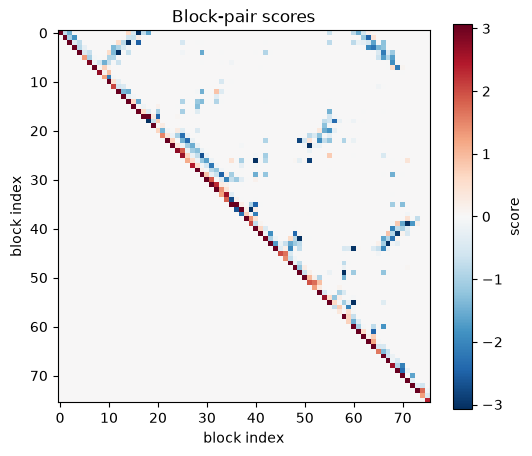

In [20]:
block_pair_scorer = score_function.render_block_pair_scoring_module(pose_stack)
block_pair_scores = block_pair_scorer(pose_stack.coords)

# Print the energy between residues 4 and 5 on pose 0
print(f"Score: {block_pair_scores[0, 4, 5]}")

import matplotlib.pyplot as plt
import numpy as np

scores = block_pair_scores[0].detach().cpu().numpy()
score_limit = np.percentile(np.abs(scores), 99)  # compress outliers for contrast

fig, ax = plt.subplots(figsize=(6, 5))
heatmap = ax.imshow(scores, cmap="RdBu_r", vmin=-score_limit, vmax=score_limit)
ax.set(xlabel="block index", ylabel="block index", title="Block-pair scores")
fig.colorbar(heatmap, ax=ax, label="score")
plt.show()


#### Interface energies

We briefly switch to a two-chain example, [1BL8](https://www.rcsb.org/structure/1BL8), to score the interface between its chains A and B. Chain masks like the ones below are the general boolean-selection mechanism that the Selections notebook covers in depth.

In [21]:
interface_cif_text = fetch_cif("1BL8")
interface_pose_stack = pose_stack_from_file(io.StringIO(interface_cif_text), device)

chain_a = select_blocks_from_pose_stack(interface_pose_stack, "[*,A,*]")
chain_b = select_blocks_from_pose_stack(interface_pose_stack, "[*,B,*]")

interface_score = calculate_block_pair_ddg(
    interface_pose_stack, chain_a, chain_b,
    sfxn=score_function, minimize=False,
)
print(f"chain A: {int(chain_a.sum())} blocks, chain B: {int(chain_b.sum())} blocks")
print(f"A-B interface score: {float(interface_score[0]):.2f}")

chain_a_atom_mask = select_from_pose_stack(interface_pose_stack, "[0,A,*]")[0][interface_pose_stack.real_atoms[0]]
viewer = tmol.view(interface_pose_stack, highlighted=chain_a_atom_mask)
viewer.show()

chain A: 100 blocks, chain B: 97 blocks
A-B interface score: 83.06


/home/runner/work/tmol/tmol/.venv/lib/python3.12/site-packages/biotite/structure/io/pdb/file.py:629: DeprecationWarning: The chararray class is deprecated and will be removed in a future release. Use an ndarray with a string or bytes dtype instead.
  record = np.char.array(np.where(array.hetero, "HETATM", "ATOM"))


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

#### Per-residue energies

`tmol.ops.per_residue_block_pair_energies` splits each block-pair score evenly between its two partner residues, so the per-residue sum reconciles exactly with the whole-pose total. It only reduces over the block dimensions, so a per-term (`sum_terms=False`) input comes back with its term dimension still unsummed.

In [22]:
per_residue_scores = per_residue_block_pair_energies(block_pair_scores)

print(f"residue score for residue 10 {float(per_residue_scores[0, 10]):7.2f}")

residue score for residue 10    3.11


### Minimization

tmol provides 2 different methods of minimizing energies - cartesian and torsion-space minimzation.

#### Cartesian-space minimization

Cartesian space minimization can be run with `tmol.run_cart_min(pose_stack, score_function)`. This will compute gradients for the XYZ coordinates of each atom directly, and will move these XYZ coordinates based on those gradients.

In [23]:
# Minimize the pose_stack
cart_minimized = tmol.run_cart_min(pose_stack.clone(), score_function)

# Score it and print the result.
cart_minimized_score = score_function.render_whole_pose_scoring_module(cart_minimized)(cart_minimized.coords)
print(f"before: {float(total_score[0]):.2f}  after: {float(cart_minimized_score[0].detach()):.2f}")

display(tmol.overlay_view(
    {"original": pose_stack, "cartesian minimized": cart_minimized},
    notes={
        "original": f"score: {float(total_score[0]):.2f}",
        "cartesian minimized": f"score: {float(cart_minimized_score[0].detach()):.2f}",
    },
))

before: 195.06  after: -242.64


/home/runner/work/tmol/tmol/.venv/lib/python3.12/site-packages/biotite/structure/io/pdb/file.py:629: DeprecationWarning: The chararray class is deprecated and will be removed in a future release. Use an ndarray with a string or bytes dtype instead.
  record = np.char.array(np.where(array.hetero, "HETATM", "ATOM"))
/home/runner/work/tmol/tmol/.venv/lib/python3.12/site-packages/biotite/structure/io/pdb/file.py:629: DeprecationWarning: The chararray class is deprecated and will be removed in a future release. Use an ndarray with a string or bytes dtype instead.
  record = np.char.array(np.where(array.hetero, "HETATM", "ATOM"))
/home/runner/work/tmol/tmol/.venv/lib/python3.12/site-packages/biotite/structure/io/pdb/file.py:629: DeprecationWarning: The chararray class is deprecated and will be removed in a future release. Use an ndarray with a string or bytes dtype instead.
  record = np.char.array(np.where(array.hetero, "HETATM", "ATOM"))
/home/runner/work/tmol/tmol/.venv/lib/python3.12/sit

#### Torsion-space minimization

Torsion-space minimization moves internal degrees of freedom (bond torsions) instead of raw xyz coordinates, following a `FoldForest` -- the kinematic tree describing how motion at one bond propagates through the rest of the structure. It reuses the same coordinate gradients as above, reparameterized through that tree; the Advanced Kinematics notebook covers FoldForests in depth, so here we just build the default one.

`tmol.MoveMap` says which internal degrees of freedom are allowed to move; `move_all_named_torsions = True` with jumps left off moves every named torsion (phi/psi/chi) and nothing else.

In [24]:
fold_forest = tmol.FoldForest.reasonable_fold_forest(pose_stack)
move_map = tmol.MoveMap.from_pose_stack(pose_stack)
move_map.move_all_named_torsions = True

kin_minimized = tmol.run_kin_min(
    pose_stack.clone(), score_function, fold_forest, move_map, optimizer_kwargs={"max_iter": 10}
)
kin_minimized_score = score_function.render_whole_pose_scoring_module(kin_minimized)(kin_minimized.coords)
print(f"before: {float(total_score[0]):.2f}  after (torsion space): {float(kin_minimized_score[0].detach()):.2f}")

display(tmol.overlay_view(
    {"original": pose_stack, "torsion minimized": kin_minimized},
    notes={
        "original": f"score: {float(total_score[0]):.2f}",
        "torsion minimized": f"score (torsion space): {float(kin_minimized_score[0].detach()):.2f}",
    },
))

before: 195.06  after (torsion space): 166.70


/home/runner/work/tmol/tmol/.venv/lib/python3.12/site-packages/biotite/structure/io/pdb/file.py:629: DeprecationWarning: The chararray class is deprecated and will be removed in a future release. Use an ndarray with a string or bytes dtype instead.
  record = np.char.array(np.where(array.hetero, "HETATM", "ATOM"))
/home/runner/work/tmol/tmol/.venv/lib/python3.12/site-packages/biotite/structure/io/pdb/file.py:629: DeprecationWarning: The chararray class is deprecated and will be removed in a future release. Use an ndarray with a string or bytes dtype instead.
  record = np.char.array(np.where(array.hetero, "HETATM", "ATOM"))
/home/runner/work/tmol/tmol/.venv/lib/python3.12/site-packages/biotite/structure/io/pdb/file.py:629: DeprecationWarning: The chararray class is deprecated and will be removed in a future release. Use an ndarray with a string or bytes dtype instead.
  record = np.char.array(np.where(array.hetero, "HETATM", "ATOM"))
/home/runner/work/tmol/tmol/.venv/lib/python3.12/sit

#### Gradients

After scoring a structure, you can retreive the gradients directly, if you wish to use them outside the minimizer. 

In [25]:
# Cartesian gradients
print("Cartesian")
coords = pose_stack.coords.detach().clone().requires_grad_(True)
whole_scorer(coords).sum().backward()
atom_grad = torch.nan_to_num(coords.grad[0]).norm(dim=-1)
for atom in atom_grad.topk(10).indices.tolist():
    print(f"{atom_label(pose_stack, 0, atom)}: {float(atom_grad[atom]):.3f} per A")

# Torsion gradients: forward kinematics (dofs -> coords) feeding the scorer
print("Torsion")
kin_module = PoseStackKinematicsModule(pose_stack, fold_forest)
kin_network = KinForestSfxnNetwork(score_function, pose_stack, kin_module)
kin_network().sum().backward()
dof_grad = torch.zeros_like(kin_network.full_dofs)
dof_grad[kin_network.dof_mask] = kin_network.masked_dofs.grad

labels, nodes = torsion_labels(pose_stack, kin_module, 0)
torsion_grad = dof_grad[nodes.to(dof_grad.device), BondDOFTypes.phi_c]
for i in torsion_grad.abs().topk(10).indices.tolist():
    print(f"{labels[i]}: {float(torsion_grad[i]):.3f} per radian")

Cartesian
A 72 ARG O: 103.100 per A
A 72 ARG HG2: 97.927 per A
A 13 ILE N: 72.971 per A
A 13 ILE CB: 61.982 per A
A 13 ILE CA: 51.391 per A
A 71 LEU HA: 39.167 per A
A 71 LEU HD12: 38.615 per A
A 3 ILE C: 37.835 per A
A 15 LEU CA: 37.796 per A
A 15 LEU N: 36.287 per A
Torsion
A 39 ASP omega: -391.071 per radian
A 37 PRO phi: 388.716 per radian
A 39 ASP psi: -356.412 per radian
A 40 GLN phi: -355.549 per radian
A 36 ILE psi: 353.465 per radian
A 63 LYS phi: 338.556 per radian
A 57 SER psi: -317.825 per radian
A 63 LYS omega: 300.572 per radian
A 34 GLU psi: 298.340 per radian
A 62 GLN psi: 290.867 per radian


#### Controlling minimization with movemaps

A movemap can restrict minimization to part of a structure. `tmol.ops.res_mask_to_coord_mask` expands a block-level mask to the atom-level mask `CartesianMoveMap` needs; `MoveMap`'s `set_move_all_{mc,sc}_tors_for_blocks` setters take the block mask directly.

#### Cartesian space

In [26]:
movable_coords = select_from_pose_stack(pose_stack, "[*,A,~1-38]")  # free everything but the first half of the chain

cartesian_move_map = tmol.CartesianMoveMap(coord_mask=movable_coords)
partial_cart_min = tmol.run_cart_min(
    pose_stack.clone(), score_function,
    coord_mask=cartesian_move_map.coord_mask,
    optimizer_kwargs={"max_iter": 10},
)
moved = (partial_cart_min.coords - pose_stack.coords).norm(dim=-1)
print(f"max movement, frozen half:  {float(torch.nan_to_num(moved[~movable_coords]).max()):.4f} A")
print(f"max movement, movable half: {float(torch.nan_to_num(moved[movable_coords]).max()):.4f} A")

display(tmol.overlay_view(
    {"original": pose_stack, "partial cartesian min": partial_cart_min},
    notes={
        "original": "unminimized",
        "partial cartesian min": (
            f"max movement frozen half: {float(torch.nan_to_num(moved[~movable_coords]).max()):.4f} A, "
            f"movable half: {float(torch.nan_to_num(moved[movable_coords]).max()):.4f} A"
        ),
    },
))

max movement, frozen half:  0.0000 A
max movement, movable half: 1.2850 A


/home/runner/work/tmol/tmol/.venv/lib/python3.12/site-packages/biotite/structure/io/pdb/file.py:629: DeprecationWarning: The chararray class is deprecated and will be removed in a future release. Use an ndarray with a string or bytes dtype instead.
  record = np.char.array(np.where(array.hetero, "HETATM", "ATOM"))
/home/runner/work/tmol/tmol/.venv/lib/python3.12/site-packages/biotite/structure/io/pdb/file.py:629: DeprecationWarning: The chararray class is deprecated and will be removed in a future release. Use an ndarray with a string or bytes dtype instead.
  record = np.char.array(np.where(array.hetero, "HETATM", "ATOM"))
/home/runner/work/tmol/tmol/.venv/lib/python3.12/site-packages/biotite/structure/io/pdb/file.py:629: DeprecationWarning: The chararray class is deprecated and will be removed in a future release. Use an ndarray with a string or bytes dtype instead.
  record = np.char.array(np.where(array.hetero, "HETATM", "ATOM"))
/home/runner/work/tmol/tmol/.venv/lib/python3.12/sit

#### Torsion space

In [27]:
second_half_mask = select_blocks_from_pose_stack(pose_stack, "[*,A,~1-38]")

partial_move_map = tmol.MoveMap.from_pose_stack(pose_stack)
partial_move_map.set_move_all_mc_tors_for_blocks(second_half_mask)
partial_move_map.set_move_all_sc_tors_for_blocks(second_half_mask)

partial_kin_min = tmol.run_kin_min(
    pose_stack.clone(), score_function, fold_forest, partial_move_map, optimizer_kwargs={"max_iter": 10}
)
moved = (partial_kin_min.coords.detach() - pose_stack.coords).norm(dim=-1)
print(f"max movement, frozen half:  {float(torch.nan_to_num(moved[~movable_coords]).max()):.4f} A")
print(f"max movement, movable half: {float(torch.nan_to_num(moved[movable_coords]).max()):.4f} A")

display(tmol.overlay_view(
    {"original": pose_stack, "partial torsion min": partial_kin_min},
    notes={
        "original": "unminimized",
        "partial torsion min": (
            f"max movement frozen half: {float(torch.nan_to_num(moved[~movable_coords]).max()):.4f} A, "
            f"movable half: {float(torch.nan_to_num(moved[movable_coords]).max()):.4f} A"
        ),
    },
))

max movement, frozen half:  0.0000 A
max movement, movable half: 1.2953 A


/home/runner/work/tmol/tmol/.venv/lib/python3.12/site-packages/biotite/structure/io/pdb/file.py:629: DeprecationWarning: The chararray class is deprecated and will be removed in a future release. Use an ndarray with a string or bytes dtype instead.
  record = np.char.array(np.where(array.hetero, "HETATM", "ATOM"))
/home/runner/work/tmol/tmol/.venv/lib/python3.12/site-packages/biotite/structure/io/pdb/file.py:629: DeprecationWarning: The chararray class is deprecated and will be removed in a future release. Use an ndarray with a string or bytes dtype instead.
  record = np.char.array(np.where(array.hetero, "HETATM", "ATOM"))
/home/runner/work/tmol/tmol/.venv/lib/python3.12/site-packages/biotite/structure/io/pdb/file.py:629: DeprecationWarning: The chararray class is deprecated and will be removed in a future release. Use an ndarray with a string or bytes dtype instead.
  record = np.char.array(np.where(array.hetero, "HETATM", "ATOM"))
/home/runner/work/tmol/tmol/.venv/lib/python3.12/sit

### Packing

#### Defining packer behavior with a PackerTask

To run packing, we must create a `PackerTask`. This controls what rotamers are to be considered at which positions.

In [28]:
default_task = PackerTask(pose_stack, PackerPalette())
default_task.restrict_to_repacking()
default_task.add_conformer_sampler(create_dunbrack_sampler_from_database(param_db, device))
default_task.add_conformer_sampler(FixedAAChiSampler())
default_task.add_conformer_sampler(IncludeCurrentSampler())
print("packer task ready: every position repackable")

packer task ready: every position repackable


#### Run packing

`pack_rotamers` runs the actual search and returns a new `PoseStack`. Even on an already-refined structure, long flexible side chains like Arg and Lys often settle into a different, better-scoring rotamer -- visible in the viewer below.

In [29]:
torch.manual_seed(SEED)
repacked = pack_rotamers(pose_stack, score_function, default_task)
repacked_score = score_function.render_whole_pose_scoring_module(repacked)(repacked.coords)
print(f"before: {float(total_score[0]):.2f}  after repack: {float(repacked_score[0]):.2f}")

display(tmol.overlay_view(
    {"original": pose_stack, "repacked": repacked},
    notes={
        "original": f"score: {float(total_score[0]):.2f}",
        "repacked": f"score: {float(repacked_score[0]):.2f}",
    },
))

before: 195.06  after repack: -92.89


/home/runner/work/tmol/tmol/.venv/lib/python3.12/site-packages/biotite/structure/io/pdb/file.py:629: DeprecationWarning: The chararray class is deprecated and will be removed in a future release. Use an ndarray with a string or bytes dtype instead.
  record = np.char.array(np.where(array.hetero, "HETATM", "ATOM"))
/home/runner/work/tmol/tmol/.venv/lib/python3.12/site-packages/biotite/structure/io/pdb/file.py:629: DeprecationWarning: The chararray class is deprecated and will be removed in a future release. Use an ndarray with a string or bytes dtype instead.
  record = np.char.array(np.where(array.hetero, "HETATM", "ATOM"))
/home/runner/work/tmol/tmol/.venv/lib/python3.12/site-packages/biotite/structure/io/pdb/file.py:629: DeprecationWarning: The chararray class is deprecated and will be removed in a future release. Use an ndarray with a string or bytes dtype instead.
  record = np.char.array(np.where(array.hetero, "HETATM", "ATOM"))
/home/runner/work/tmol/tmol/.venv/lib/python3.12/sit

`OptHSampler` samples proton chis and amide/ring flips only, leaving every heavy atom at its input position -- add it (never alongside a Dunbrack sampler on the same position) for hydrogen-only packing.

In [30]:
opth_task = PackerTask(pose_stack, PackerPalette())
opth_task.restrict_to_repacking()
opth_task.add_conformer_sampler(IncludeCurrentSampler())
opth_task.add_conformer_sampler(OptHSampler())
opth_task.add_conformer_sampler(FixedAAChiSampler())

torch.manual_seed(SEED)
opth_packed = pack_rotamers(pose_stack, score_function, opth_task)
opth_score = score_function.render_whole_pose_scoring_module(opth_packed)(opth_packed.coords)
print(f"before: {float(total_score[0]):.2f}  after optH-only pack: {float(opth_score[0]):.2f}")

display(tmol.overlay_view(
    {"original": pose_stack, "optH-only packed": opth_packed},
    notes={
        "original": f"score: {float(total_score[0]):.2f}",
        "optH-only packed": f"score: {float(opth_score[0]):.2f}",
    },
))

before: 195.06  after optH-only pack: 194.80


/home/runner/work/tmol/tmol/.venv/lib/python3.12/site-packages/biotite/structure/io/pdb/file.py:629: DeprecationWarning: The chararray class is deprecated and will be removed in a future release. Use an ndarray with a string or bytes dtype instead.
  record = np.char.array(np.where(array.hetero, "HETATM", "ATOM"))
/home/runner/work/tmol/tmol/.venv/lib/python3.12/site-packages/biotite/structure/io/pdb/file.py:629: DeprecationWarning: The chararray class is deprecated and will be removed in a future release. Use an ndarray with a string or bytes dtype instead.
  record = np.char.array(np.where(array.hetero, "HETATM", "ATOM"))
/home/runner/work/tmol/tmol/.venv/lib/python3.12/site-packages/biotite/structure/io/pdb/file.py:629: DeprecationWarning: The chararray class is deprecated and will be removed in a future release. Use an ndarray with a string or bytes dtype instead.
  record = np.char.array(np.where(array.hetero, "HETATM", "ATOM"))
/home/runner/work/tmol/tmol/.venv/lib/python3.12/sit

#### Controlling packing at the residue level

`disable_packing_by_block_mask` restricts the search to specific positions; everything else keeps its input conformation untouched.

In [31]:
single_residue_task = PackerTask(pose_stack, PackerPalette())
single_residue_task.restrict_to_repacking()
shell = select_blocks_from_pose_stack(pose_stack, "[*,A,11]")
single_residue_task.disable_packing_by_block_mask(~shell)
single_residue_task.add_conformer_sampler(create_dunbrack_sampler_from_database(param_db, device))
single_residue_task.add_conformer_sampler(FixedAAChiSampler())
single_residue_task.add_conformer_sampler(IncludeCurrentSampler())

torch.manual_seed(SEED)
single_packed = pack_rotamers(pose_stack, score_function, single_residue_task)
moved = (single_packed.coords - pose_stack.coords).norm(dim=-1)[0]
outside_residue = select_from_pose_stack(pose_stack, "[0,A,~11]")[0]
print(f"max movement outside residue A[11]: {float(torch.nan_to_num(moved[outside_residue]).max()):.4f} A")

display(tmol.overlay_view(
    {"original": pose_stack, "single-residue packed": single_packed},
    notes={
        "original": "residue A[11] unpacked",
        "single-residue packed": (
            "max movement outside residue A[11]: "
            f"{float(torch.nan_to_num(moved[outside_residue]).max()):.4f} A"
        ),
    },
))

max movement outside residue A[11]: 0.0000 A


/home/runner/work/tmol/tmol/.venv/lib/python3.12/site-packages/biotite/structure/io/pdb/file.py:629: DeprecationWarning: The chararray class is deprecated and will be removed in a future release. Use an ndarray with a string or bytes dtype instead.
  record = np.char.array(np.where(array.hetero, "HETATM", "ATOM"))
/home/runner/work/tmol/tmol/.venv/lib/python3.12/site-packages/biotite/structure/io/pdb/file.py:629: DeprecationWarning: The chararray class is deprecated and will be removed in a future release. Use an ndarray with a string or bytes dtype instead.
  record = np.char.array(np.where(array.hetero, "HETATM", "ATOM"))
/home/runner/work/tmol/tmol/.venv/lib/python3.12/site-packages/biotite/structure/io/pdb/file.py:629: DeprecationWarning: The chararray class is deprecated and will be removed in a future release. Use an ndarray with a string or bytes dtype instead.
  record = np.char.array(np.where(array.hetero, "HETATM", "ATOM"))
/home/runner/work/tmol/tmol/.venv/lib/python3.12/sit

### Relax

`tmol.fast_relax` alternates packing and minimization over a multi-stage schedule, instead of running either once. It needs a `PackerPalette`, a movemap, and a `FoldForest`, all already introduced above.

#### Relax options (cycles, schedule)

`num_repeats` controls how many times the full schedule runs; `schedule` is a list of stages, each ramping `fa_rep` (and, if constraints are active, their weight) from mild to full strength -- packing near-clashing structures directly at full repulsive weight tends to get stuck. Omit `schedule` for the built-in default schedule.

In [32]:
from tmol.relax import DEFAULT_RELAX_SCHEDULE

quick_schedule = [
    {"fa_rep_pack_frac": 0.10, "fa_rep_min_frac": 0.20, "cst_frac": 1.0},
    {"fa_rep_pack_frac": 1.00, "fa_rep_min_frac": 1.00, "cst_frac": 0.0},
]
print(f"a 2-stage schedule; the default schedule has {len(DEFAULT_RELAX_SCHEDULE)} stages")

a 2-stage schedule; the default schedule has 4 stages


#### Cartesian relax

Passing a `CartesianMoveMap` relaxes in cartesian space.

In [33]:
palette = PackerPalette()
full_cartesian_move_map = tmol.CartesianMoveMap()

torch.manual_seed(SEED)
cart_relaxed = tmol.fast_relax(
    pose_stack.clone(), score_function, palette, full_cartesian_move_map, fold_forest,
    num_repeats=1, schedule=quick_schedule,
)
cart_relaxed_score = score_function.render_whole_pose_scoring_module(cart_relaxed)(cart_relaxed.coords)
print(f"before: {float(total_score[0]):.2f}  after cartesian relax: {float(cart_relaxed_score[0].detach()):.2f}")

display(tmol.overlay_view(
    {"original": pose_stack, "cartesian relaxed": cart_relaxed},
    notes={
        "original": f"score: {float(total_score[0]):.2f}",
        "cartesian relaxed": f"score: {float(cart_relaxed_score[0].detach()):.2f}",
    },
))

before: 195.06  after cartesian relax: -273.74


/home/runner/work/tmol/tmol/.venv/lib/python3.12/site-packages/biotite/structure/io/pdb/file.py:629: DeprecationWarning: The chararray class is deprecated and will be removed in a future release. Use an ndarray with a string or bytes dtype instead.
  record = np.char.array(np.where(array.hetero, "HETATM", "ATOM"))
/home/runner/work/tmol/tmol/.venv/lib/python3.12/site-packages/biotite/structure/io/pdb/file.py:629: DeprecationWarning: The chararray class is deprecated and will be removed in a future release. Use an ndarray with a string or bytes dtype instead.
  record = np.char.array(np.where(array.hetero, "HETATM", "ATOM"))
/home/runner/work/tmol/tmol/.venv/lib/python3.12/site-packages/biotite/structure/io/pdb/file.py:629: DeprecationWarning: The chararray class is deprecated and will be removed in a future release. Use an ndarray with a string or bytes dtype instead.
  record = np.char.array(np.where(array.hetero, "HETATM", "ATOM"))
/home/runner/work/tmol/tmol/.venv/lib/python3.12/sit

#### Torsion relax

Passing a `MoveMap` instead relaxes in torsion space -- but `fast_relax`'s minimization step always runs `run_cart_min` internally unless told otherwise, so a torsion-space relax also needs a `min_fn` callable wrapping `tmol.run_kin_min` with our fold forest and move map.

In [34]:
def kin_min_fn(ps, sfxn, *, fold_forest, move_map, verbose):
    return tmol.run_kin_min(ps, sfxn, fold_forest, move_map, verbose=verbose)


torch.manual_seed(SEED)
kin_relaxed = tmol.fast_relax(
    pose_stack.clone(), score_function, palette, move_map, fold_forest,
    num_repeats=1, schedule=quick_schedule, min_fn=kin_min_fn,
)
kin_relaxed_score = score_function.render_whole_pose_scoring_module(kin_relaxed)(kin_relaxed.coords)
print(f"before: {float(total_score[0]):.2f}  after torsion relax: {float(kin_relaxed_score[0].detach()):.2f}")

display(tmol.overlay_view(
    {"original": pose_stack, "torsion relaxed": kin_relaxed},
    notes={
        "original": f"score: {float(total_score[0]):.2f}",
        "torsion relaxed": f"score: {float(kin_relaxed_score[0].detach()):.2f}",
    },
))

before: 195.06  after torsion relax: -174.36


/home/runner/work/tmol/tmol/.venv/lib/python3.12/site-packages/biotite/structure/io/pdb/file.py:629: DeprecationWarning: The chararray class is deprecated and will be removed in a future release. Use an ndarray with a string or bytes dtype instead.
  record = np.char.array(np.where(array.hetero, "HETATM", "ATOM"))
/home/runner/work/tmol/tmol/.venv/lib/python3.12/site-packages/biotite/structure/io/pdb/file.py:629: DeprecationWarning: The chararray class is deprecated and will be removed in a future release. Use an ndarray with a string or bytes dtype instead.
  record = np.char.array(np.where(array.hetero, "HETATM", "ATOM"))
/home/runner/work/tmol/tmol/.venv/lib/python3.12/site-packages/biotite/structure/io/pdb/file.py:629: DeprecationWarning: The chararray class is deprecated and will be removed in a future release. Use an ndarray with a string or bytes dtype instead.
  record = np.char.array(np.where(array.hetero, "HETATM", "ATOM"))
/home/runner/work/tmol/tmol/.venv/lib/python3.12/sit

#### Relax with a movemap

The movemap restricts *minimization* as before, but `fast_relax` also repacks every cycle regardless of the movemap -- freezing a region completely needs `task_operations` to disable packing there too.

In [35]:
restricted_move_map = tmol.CartesianMoveMap(coord_mask=movable_coords)
second_half_mask = select_blocks_from_pose_stack(pose_stack, "[*,A,~1-38]")


def freeze_first_half(task):
    task.disable_packing_by_block_mask(~second_half_mask)


torch.manual_seed(SEED)
restricted_relaxed = tmol.fast_relax(
    pose_stack.clone(), score_function, palette, restricted_move_map, fold_forest,
    num_repeats=1, schedule=quick_schedule, task_operations=[freeze_first_half],
)
moved = (restricted_relaxed.coords - pose_stack.coords).norm(dim=-1)
print(f"max movement, frozen half:  {float(torch.nan_to_num(moved[~movable_coords]).max()):.4f} A")
print(f"max movement, movable half: {float(torch.nan_to_num(moved[movable_coords]).max()):.4f} A")

display(tmol.overlay_view(
    {"original": pose_stack, "movemap-restricted relax": restricted_relaxed},
    notes={
        "original": "unrelaxed",
        "movemap-restricted relax": (
            f"max movement frozen half: {float(torch.nan_to_num(moved[~movable_coords]).max()):.4f} A, "
            f"movable half: {float(torch.nan_to_num(moved[movable_coords]).max()):.4f} A"
        ),
    },
))

max movement, frozen half:  0.0000 A
max movement, movable half: 2.6188 A


/home/runner/work/tmol/tmol/.venv/lib/python3.12/site-packages/biotite/structure/io/pdb/file.py:629: DeprecationWarning: The chararray class is deprecated and will be removed in a future release. Use an ndarray with a string or bytes dtype instead.
  record = np.char.array(np.where(array.hetero, "HETATM", "ATOM"))
/home/runner/work/tmol/tmol/.venv/lib/python3.12/site-packages/biotite/structure/io/pdb/file.py:629: DeprecationWarning: The chararray class is deprecated and will be removed in a future release. Use an ndarray with a string or bytes dtype instead.
  record = np.char.array(np.where(array.hetero, "HETATM", "ATOM"))
/home/runner/work/tmol/tmol/.venv/lib/python3.12/site-packages/biotite/structure/io/pdb/file.py:629: DeprecationWarning: The chararray class is deprecated and will be removed in a future release. Use an ndarray with a string or bytes dtype instead.
  record = np.char.array(np.where(array.hetero, "HETATM", "ATOM"))
/home/runner/work/tmol/tmol/.venv/lib/python3.12/sit

#### Relax with constraints

`create_mainchain_coordinate_constraints` attaches a harmonic restraint on every mainchain atom to its current position; `fast_relax` ramps the `constraint` weight down over the schedule (`cst_frac`) as long as that `ScoreType`'s weight is nonzero.

In [36]:
score_function.set_weight(ScoreType.constraint, 1.0)
constrained_start = create_mainchain_coordinate_constraints(pose_stack.clone())

torch.manual_seed(SEED)
constrained_relaxed = tmol.fast_relax(
    constrained_start, score_function, palette, full_cartesian_move_map, fold_forest,
    num_repeats=1, schedule=quick_schedule,
)
constrained_score = score_function.render_whole_pose_scoring_module(constrained_relaxed)(constrained_relaxed.coords)
print(f"before: {float(total_score[0]):.2f}  after constrained relax: {float(constrained_score[0].detach()):.2f}")

display(tmol.overlay_view(
    {"constrained start": constrained_start, "constrained relaxed": constrained_relaxed},
    notes={
        "constrained start": f"score: {float(total_score[0]):.2f}",
        "constrained relaxed": f"score: {float(constrained_score[0].detach()):.2f}",
    },
))

before: 195.06  after constrained relax: -272.02


/home/runner/work/tmol/tmol/.venv/lib/python3.12/site-packages/biotite/structure/io/pdb/file.py:629: DeprecationWarning: The chararray class is deprecated and will be removed in a future release. Use an ndarray with a string or bytes dtype instead.
  record = np.char.array(np.where(array.hetero, "HETATM", "ATOM"))
/home/runner/work/tmol/tmol/.venv/lib/python3.12/site-packages/biotite/structure/io/pdb/file.py:629: DeprecationWarning: The chararray class is deprecated and will be removed in a future release. Use an ndarray with a string or bytes dtype instead.
  record = np.char.array(np.where(array.hetero, "HETATM", "ATOM"))
/home/runner/work/tmol/tmol/.venv/lib/python3.12/site-packages/biotite/structure/io/pdb/file.py:629: DeprecationWarning: The chararray class is deprecated and will be removed in a future release. Use an ndarray with a string or bytes dtype instead.
  record = np.char.array(np.where(array.hetero, "HETATM", "ATOM"))
/home/runner/work/tmol/tmol/.venv/lib/python3.12/sit

## 3. Metals and Nucleic Acids

Metal ions and nucleic acids both score correctly with no special setup -- this notebook is mostly worked examples confirming that. It assumes the basics from [section 1](#1.-basics) and scoring/relax from [section 2](#2.-scoring-and-optimization).

### Metals

#### Handled by default

Metal ions (ZN, CA, MG, FE, ...) are ordinary residue types in the default chemical database, not ligands -- detecting a metal ion and building its coordinating bonds needs no `prepare_ligands` flag. A `MetalCoordination` energy term scoring that geometry is included in `beta2016_score_function` by default, at weight 1.0.

We use a small curated fixture from TMol's own test suite -- a tetrahedral zinc site from [3KS3](https://www.rcsb.org/structure/3KS3) (carbonic anhydrase II) -- rather than fetching the full deposited structure, since it's already cropped to the site of interest.

In [37]:
metal_pose_stack = pose_stack_from_file(data_path("metal_fixtures", "zn_tetrahedral_3ks3.cif.zst"), device)
print(f"n_poses={metal_pose_stack.n_poses}, max_n_blocks={metal_pose_stack.max_n_blocks}")

viewer = tmol.view(metal_pose_stack)
viewer.show()

n_poses=1, max_n_blocks=258


/home/runner/work/tmol/tmol/.venv/lib/python3.12/site-packages/biotite/structure/io/pdb/file.py:629: DeprecationWarning: The chararray class is deprecated and will be removed in a future release. Use an ndarray with a string or bytes dtype instead.
  record = np.char.array(np.where(array.hetero, "HETATM", "ATOM"))


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

#### Query metal coordination

On structure load, tmol infers coordinating atoms, and -- based on their geometry and the metal type -- infers coordination geometry.  The code below queries the resulting metal coordination type (via `pose_stack.block_type`) and connections (via the `site_connections` of each entry in `bt.metal_sites` and `pose_stack.inter_residue_connections64`), printing out -- for each metal -- the determined coordinations and coordinating atoms.

In [38]:
def metal_sites(pose_stack, pose, block):
    """(metal atom, geometry, donor labels) for each metal in a block; None marks an open site."""
    bt = pose_stack.block_type(pose, block)
    result = []
    for site in bt.metal_sites:
        donors = []
        for conn_name in site.site_connections:
            conn = bt.connection_to_cidx[conn_name]
            partner, partner_conn = pose_stack.inter_residue_connections64[pose, block, conn].tolist()
            if partner < 0:
                donors.append(None)
                continue
            partner_bt = pose_stack.block_type(pose, partner)
            atom = partner_bt.atoms[partner_bt.ordered_connection_atoms[partner_conn]].name
            donors.append(f"{residue_label(pose_stack, pose, partner)} {atom}")
        result.append((site.metal_atom, site.geometry, donors))
    return result

cif_text = fetch_cif("3F7L")
pose_stack = pose_stack_from_file(io.StringIO(cif_text), device)
metals = metal_blocks(pose_stack, 0)

# Coordination found at construction
for block in metals:
    for metal_atom, geometry, donors in metal_sites(pose_stack, 0, block):
        print(f"{residue_label(pose_stack, 0, block)} {metal_atom} ({geometry}):")
        for site, donor in enumerate(donors):
            print(f"    site {site}: {donor or 'open'}")

A 201 CU1 CU (trigonal):
    site 0: A 44 HIS ND1
    site 1: A 46 HIS NE2
    site 2: A 118 HIS NE2
A 203 ZN ZN (tetrahedral):
    site 0: A 61 HIS ND1
    site 1: A 69 HIS ND1
    site 2: A 81 ASP OD1
    site 3: A 78 HIS ND1
A 204 NA NA (irregular):
    site 0: A 90 ASP OD1
    site 1: open
    site 2: open
    site 3: open
    site 4: open
    site 5: open
    site 6: open
    site 7: open


Relax the structure and compare each metal's `metal_coordination` energy before and after.

In [39]:
score_function = beta2016_score_function(device)
metal_coordination_index = score_function.all_score_types().index(ScoreType.metal_coordination)
before = block_energies(score_function, pose_stack, ScoreType.metal_coordination, 0, metals)

torch.manual_seed(SEED)
relaxed = tmol.fast_relax(
    pose_stack.clone(),
    score_function,
    PackerPalette(),
    tmol.CartesianMoveMap(),
    tmol.FoldForest.reasonable_fold_forest(pose_stack),
    num_repeats=1,
)
after = block_energies(score_function, relaxed, ScoreType.metal_coordination, 0, metals)

summary = []
for block, e0, e1 in zip(metals, before, after):
    summary.append(f"{residue_label(pose_stack, 0, block)}: {e0:.2f} -> {e1:.2f}")
    print(f"metal_coordination {summary[-1]}")

display(tmol.overlay_view(
    {"original": pose_stack, "relaxed": relaxed},
    notes={"original": "pre-relax", "relaxed": "metal_coordination " + "; ".join(summary)},
))

metal_coordination A 201 CU1: 1.78 -> 0.42
metal_coordination A 203 ZN: 1.08 -> 0.26
metal_coordination A 204 NA: 21.39 -> 0.02


/home/runner/work/tmol/tmol/.venv/lib/python3.12/site-packages/biotite/structure/io/pdb/file.py:629: DeprecationWarning: The chararray class is deprecated and will be removed in a future release. Use an ndarray with a string or bytes dtype instead.
  record = np.char.array(np.where(array.hetero, "HETATM", "ATOM"))
/home/runner/work/tmol/tmol/.venv/lib/python3.12/site-packages/biotite/structure/io/pdb/file.py:629: DeprecationWarning: The chararray class is deprecated and will be removed in a future release. Use an ndarray with a string or bytes dtype instead.
  record = np.char.array(np.where(array.hetero, "HETATM", "ATOM"))
/home/runner/work/tmol/tmol/.venv/lib/python3.12/site-packages/biotite/structure/io/pdb/file.py:629: DeprecationWarning: The chararray class is deprecated and will be removed in a future release. Use an ndarray with a string or bytes dtype instead.
  record = np.char.array(np.where(array.hetero, "HETATM", "ATOM"))
/home/runner/work/tmol/tmol/.venv/lib/python3.12/sit

#### Metal cluster example

Multi-ion cofactors (iron-sulfur clusters, and similar) are supported the same way -- still no `prepare_ligands` flag, no cluster-specific API. Here a [2Fe-2S] cluster from a ferredoxin ([6E6R](https://www.rcsb.org/structure/6E6R)), each iron coordinated by two cysteines.

In [40]:
fes_pose_stack = pose_stack_from_file(data_path("metal_fixtures", "fes_ferredoxin_6e6r.cif.zst"), device)
fes_score_function = beta2016_score_function(device, param_db=param_db)
fes_scorer = fes_score_function.render_whole_pose_scoring_module(fes_pose_stack)
fes_weighted_terms = fes_scorer(fes_pose_stack.coords, sum_terms=False)
print(f"n_poses={fes_pose_stack.n_poses}, max_n_blocks={fes_pose_stack.max_n_blocks}")
print(f"metal_coordination energy: {float(fes_weighted_terms[metal_coordination_index, 0]):.2f}")

viewer = tmol.view(fes_pose_stack)
viewer.show()

n_poses=1, max_n_blocks=57
metal_coordination energy: 37.32


/home/runner/work/tmol/tmol/.venv/lib/python3.12/site-packages/biotite/structure/io/pdb/file.py:629: DeprecationWarning: The chararray class is deprecated and will be removed in a future release. Use an ndarray with a string or bytes dtype instead.
  record = np.char.array(np.where(array.hetero, "HETATM", "ATOM"))


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

### Nucleic acids

#### Handled by default

DNA and RNA residues are likewise ordinary chemistry in the default database. An `NaTorsion` term scoring their backbone, sugar-pucker, and glycosidic torsions is included in `beta2016_score_function` by default; it's an exact zero on protein-only poses, so mixed protein/NA structures score correctly with no special handling either.

#### Example

[1HDD](https://www.rcsb.org/structure/1HDD), an engrailed homeodomain bound to its DNA operator, gives us both an NA torsion energy and a protein-DNA interface in one structure.

In [41]:
dna_cif_text = fetch_cif("1HDD")
dna_pose_stack = pose_stack_from_file(io.StringIO(dna_cif_text), device)
print(f"n_poses={dna_pose_stack.n_poses}, max_n_blocks={dna_pose_stack.max_n_blocks}")

viewer = tmol.view(dna_pose_stack)
viewer.show()

na_score_function = beta2016_score_function(device, param_db=param_db)
na_fold_forest = tmol.FoldForest.reasonable_fold_forest(dna_pose_stack)

torch.manual_seed(SEED)
dna_relaxed = tmol.fast_relax(
    dna_pose_stack.clone(), na_score_function, PackerPalette(), tmol.CartesianMoveMap(), na_fold_forest,
    num_repeats=1,
)
dna_scorer = na_score_function.render_whole_pose_scoring_module(dna_relaxed)
dna_weighted_terms = dna_scorer(dna_relaxed.coords, sum_terms=False)
na_torsion_index = na_score_function.all_score_types().index(ScoreType.na_torsion)
print(f"na_torsion energy: {float(dna_weighted_terms[na_torsion_index, 0].detach()):.2f}")

display(tmol.overlay_view(
    {"original": dna_pose_stack, "relaxed": dna_relaxed},
    notes={
        "original": "pre-relax",
        "relaxed": f"na_torsion energy: {float(dna_weighted_terms[na_torsion_index, 0].detach()):.2f}",
    },
))

n_poses=1, max_n_blocks=156


/home/runner/work/tmol/tmol/.venv/lib/python3.12/site-packages/biotite/structure/io/pdb/file.py:629: DeprecationWarning: The chararray class is deprecated and will be removed in a future release. Use an ndarray with a string or bytes dtype instead.
  record = np.char.array(np.where(array.hetero, "HETATM", "ATOM"))


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

na_torsion energy: 33.05


/home/runner/work/tmol/tmol/.venv/lib/python3.12/site-packages/biotite/structure/io/pdb/file.py:629: DeprecationWarning: The chararray class is deprecated and will be removed in a future release. Use an ndarray with a string or bytes dtype instead.
  record = np.char.array(np.where(array.hetero, "HETATM", "ATOM"))
/home/runner/work/tmol/tmol/.venv/lib/python3.12/site-packages/biotite/structure/io/pdb/file.py:629: DeprecationWarning: The chararray class is deprecated and will be removed in a future release. Use an ndarray with a string or bytes dtype instead.
  record = np.char.array(np.where(array.hetero, "HETATM", "ATOM"))
/home/runner/work/tmol/tmol/.venv/lib/python3.12/site-packages/biotite/structure/io/pdb/file.py:629: DeprecationWarning: The chararray class is deprecated and will be removed in a future release. Use an ndarray with a string or bytes dtype instead.
  record = np.char.array(np.where(array.hetero, "HETATM", "ATOM"))
/home/runner/work/tmol/tmol/.venv/lib/python3.12/sit

The protein-DNA interface energy reuses the block-pair scoring technique from [section 2](#2.-scoring-and-optimization), with a `polymer_type`-based mask standing in for a chain mask -- selections like this are covered in general in [section 5](#5.-selections).

In [42]:
pbt = dna_relaxed.packed_block_types
protein_mask = torch.zeros((1, dna_relaxed.max_n_blocks), dtype=torch.bool)
dna_mask = torch.zeros((1, dna_relaxed.max_n_blocks), dtype=torch.bool)
for block in range(dna_relaxed.max_n_blocks):
    bt_ind = int(dna_relaxed.block_type_ind64[0, block])
    if bt_ind < 0:
        continue
    polymer_type = pbt.active_block_types[bt_ind].properties.polymer.polymer_type
    protein_mask[0, block] = polymer_type == "amino_acid"
    dna_mask[0, block] = polymer_type == "nucleic_acid"

dna_block_scorer = na_score_function.render_block_pair_scoring_module(dna_relaxed)
dna_block_pair = dna_block_scorer(dna_relaxed.coords)[0].detach()
interface_score = (
    dna_block_pair[protein_mask[0]][:, dna_mask[0]].sum()
    + dna_block_pair[dna_mask[0]][:, protein_mask[0]].sum()
)
print(f"protein blocks: {int(protein_mask.sum())}, DNA blocks: {int(dna_mask.sum())}")
print(f"protein-DNA interface score: {float(interface_score):.2f}")

protein blocks: 114, DNA blocks: 42
protein-DNA interface score: -207.35


The same recipe works unchanged for RNA. [1EHT](https://www.rcsb.org/structure/1EHT) is a theophylline-binding RNA aptamer; here the interesting "other side" is its bound ligand rather than a second polymer chain, covered in [section 4](#4.-ligands-and-ncaas), so we report just the NA torsion energy.

In [43]:
rna_cif_text = fetch_cif("1EHT")
rna_pose_stack = pose_stack_from_file(io.StringIO(rna_cif_text), device)
print(f"n_poses={rna_pose_stack.n_poses}, max_n_blocks={rna_pose_stack.max_n_blocks}")

viewer = tmol.view(rna_pose_stack)
viewer.show()

torch.manual_seed(SEED)
rna_relaxed = tmol.fast_relax(
    rna_pose_stack.clone(), na_score_function, PackerPalette(), tmol.CartesianMoveMap(),
    tmol.FoldForest.reasonable_fold_forest(rna_pose_stack), num_repeats=1,
)
rna_scorer = na_score_function.render_whole_pose_scoring_module(rna_relaxed)
rna_weighted_terms = rna_scorer(rna_relaxed.coords, sum_terms=False)
print(f"na_torsion energy: {float(rna_weighted_terms[na_torsion_index, 0].detach()):.2f}")

display(tmol.overlay_view(
    {"original": rna_pose_stack, "relaxed": rna_relaxed},
    notes={
        "original": "pre-relax",
        "relaxed": f"na_torsion energy: {float(rna_weighted_terms[na_torsion_index, 0].detach()):.2f}",
    },
))

n_poses=1, max_n_blocks=33


/home/runner/work/tmol/tmol/.venv/lib/python3.12/site-packages/biotite/structure/io/pdb/file.py:629: DeprecationWarning: The chararray class is deprecated and will be removed in a future release. Use an ndarray with a string or bytes dtype instead.
  record = np.char.array(np.where(array.hetero, "HETATM", "ATOM"))


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

na_torsion energy: 62.69


/home/runner/work/tmol/tmol/.venv/lib/python3.12/site-packages/biotite/structure/io/pdb/file.py:629: DeprecationWarning: The chararray class is deprecated and will be removed in a future release. Use an ndarray with a string or bytes dtype instead.
  record = np.char.array(np.where(array.hetero, "HETATM", "ATOM"))
/home/runner/work/tmol/tmol/.venv/lib/python3.12/site-packages/biotite/structure/io/pdb/file.py:629: DeprecationWarning: The chararray class is deprecated and will be removed in a future release. Use an ndarray with a string or bytes dtype instead.
  record = np.char.array(np.where(array.hetero, "HETATM", "ATOM"))
/home/runner/work/tmol/tmol/.venv/lib/python3.12/site-packages/biotite/structure/io/pdb/file.py:629: DeprecationWarning: The chararray class is deprecated and will be removed in a future release. Use an ndarray with a string or bytes dtype instead.
  record = np.char.array(np.where(array.hetero, "HETATM", "ATOM"))
/home/runner/work/tmol/tmol/.venv/lib/python3.12/sit

## 4. Ligands and NCAAs

Small-molecule ligands and non-canonical amino acids both go through the same preparation pipeline (`prepare_ligands=True`) seen briefly in section 1. This notebook goes further: reusing prepared chemistry, saving/loading it, splitting a ligand into independently-scored fragments, and the handful of NCAAs that don't need the pipeline at all.

### Ligands

#### Automatic pipeline

We return to [3PTB](https://www.rcsb.org/structure/3PTB) (trypsin + the small-molecule inhibitor benzamidine, BEN) from section 1 and go further, relaxing the whole complex.

In [44]:
from tmol import atom_array_from_file, pose_stack_from_atom_array

ligand_cif_text = fetch_cif("3PTB")
ligand_structure = atom_array_from_file(io.StringIO(ligand_cif_text))
pose_stack, build_context = pose_stack_from_atom_array(
    ligand_structure, device, prepare_ligands=True, param_db=param_db, return_context=True
)
score_function = beta2016_score_function(device, param_db=build_context.parameter_database)
fold_forest = tmol.FoldForest.reasonable_fold_forest(pose_stack)

torch.manual_seed(SEED)
relaxed = tmol.fast_relax(
    pose_stack.clone(), score_function, PackerPalette(), tmol.CartesianMoveMap(), fold_forest, num_repeats=1
)
print(f"n_poses={relaxed.n_poses}, max_n_blocks={relaxed.max_n_blocks}")

ligand_atom_mask = res_mask_to_coord_mask(relaxed, tmol.get_ligand_mask(relaxed))
viewer = tmol.view(relaxed, highlighted=ligand_atom_mask[relaxed.real_atoms])
viewer.show()

n_poses=1, max_n_blocks=225


/home/runner/work/tmol/tmol/.venv/lib/python3.12/site-packages/biotite/structure/io/pdb/file.py:629: DeprecationWarning: The chararray class is deprecated and will be removed in a future release. Use an ndarray with a string or bytes dtype instead.
  record = np.char.array(np.where(array.hetero, "HETATM", "ATOM"))


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

#### Interaction energy

`tmol.ops.calculate_block_pair_ddg` sums the cross-mask block-pair interaction between a residue mask and everything else -- here, between the ligand block and the rest of the complex. (Despite its name it reports that raw interaction, not a true bound/unbound ddG.)

In [45]:
ligand_mask = torch.zeros((1, relaxed.max_n_blocks), dtype=torch.bool)
for block in range(relaxed.max_n_blocks):
    bt_ind = int(relaxed.block_type_ind64[0, block])
    if bt_ind >= 0 and relaxed.packed_block_types.active_block_types[bt_ind].name3 == "BEN":
        ligand_mask[0, block] = True

interaction = calculate_block_pair_ddg(relaxed, ligand_mask, sfxn=score_function, minimize=False)
print(f"ligand-protein interaction energy: {float(interaction[0]):.2f}")

ligand-protein interaction energy: -27.76


#### Internal energies

`gen_torsions` is the generic-atom-type torsional term that shows up in a per-term score breakdown (see section 2) -- it fills in wherever a residue lacks dedicated per-residue cartbonded parameters (canonical amino acids score an exact zero here), which in practice means ligands and other novel chemistry. It's a reasonable proxy for "ligand strain."

In [46]:
relaxed_scorer = score_function.render_whole_pose_scoring_module(relaxed)
weighted_terms = relaxed_scorer(relaxed.coords, sum_terms=False)
gen_torsions_index = score_function.all_score_types().index(ScoreType.gen_torsions)
print(f"gen_torsions (ligand strain): {float(weighted_terms[gen_torsions_index, 0].detach()):.2f}")

gen_torsions (ligand strain): 0.63


#### Reusing a build context

Preparing a ligand's chemistry (typing, charges, conformer) is the expensive part of loading. [1BTY](https://www.rcsb.org/structure/1BTY) is a *different* trypsin-benzamidine structure -- passing the earlier `build_context` into `context=` skips re-preparing BEN entirely. `build_context_from_atom_array` extends a copy of the parameter database rather than mutating it, so the original database is untouched.

In [47]:
other_cif_text = fetch_cif("1BTY")
other_structure = atom_array_from_file(io.StringIO(other_cif_text))
other_pose_stack = pose_stack_from_atom_array(other_structure, device, context=build_context, no_optH=True)
print(f"reused context to build a second pose: {other_pose_stack.max_n_blocks} blocks, no re-preparation needed")

other_ligand_mask = res_mask_to_coord_mask(other_pose_stack, tmol.get_ligand_mask(other_pose_stack))
viewer = tmol.view(other_pose_stack, highlighted=other_ligand_mask[other_pose_stack.real_atoms])
viewer.show()

reused context to build a second pose: 225 blocks, no re-preparation needed


/home/runner/work/tmol/tmol/.venv/lib/python3.12/site-packages/biotite/structure/io/pdb/file.py:629: DeprecationWarning: The chararray class is deprecated and will be removed in a future release. Use an ndarray with a string or bytes dtype instead.
  record = np.char.array(np.where(array.hetero, "HETATM", "ATOM"))


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

#### Saving and loading `.tmol` ligand parameters

`prepare_ligands` (the lower-level function `prepare_ligands=True` calls into) can also write everything it derives for a ligand to a `.tmol` YAML file via `params_output`, given just that ligand's own atoms -- not the whole complex, since the pipeline expects a self-contained molecule.

In [48]:
import tempfile
from pathlib import Path
from tmol.ligand import prepare_ligands

ligand_only_atoms = ligand_structure[ligand_structure.res_name == "BEN"]
tmol_path = Path(tempfile.gettempdir()) / "ben.tmol"
_, _ = prepare_ligands(ligand_only_atoms, param_db=param_db, params_output=str(tmol_path), seed=SEED)
print(f"wrote {tmol_path} ({tmol_path.stat().st_size} bytes)")

wrote /tmp/ben.tmol (9484 bytes)


`inject_params_file` reads a `.tmol` file directly into a `ParameterDatabase` -- here the global default -- without touching RDKit or OpenBabel again. Loading a full complex can then skip `prepare_ligands=True` entirely and just point `ligand_params_files` at the file.

In [49]:
from tmol.ligand import inject_params_file

inject_params_file(param_db, str(tmol_path))
reloaded_pose = pose_stack_from_atom_array(
    ligand_structure, device, param_db=param_db,
    ligand_params_files=[str(tmol_path)], no_optH=True,
)
print(f"rebuilt from the saved file: {reloaded_pose.max_n_blocks} blocks")

rebuilt from the saved file: 225 blocks


#### Ligand "splitting"

A large or multi-fragment ligand can be cut into separately-tracked blocks: chemistry is perceived once for the whole molecule, and a per-atom `tmol_fragment_id` annotation (`FRAGMENT_ID_ANNOTATION`) marks which side of a chosen bond each atom falls on. There's no automatic cut-point selection -- the cut below comes from picking a bridging bond in a test fixture ligand and splitting its bond graph into the two halves that remain connected without it.

In [50]:
import numpy as np
import biotite.structure as struc
import biotite.structure.io
from tmol.ligand import FRAGMENT_ID_ANNOTATION, load_params_file
split_structure = biotite.structure.io.load_structure(
    str(data_path("protein_ligand_test", "ace.tmol.nomin.cif")), model=1, include_bonds=True
)
if isinstance(split_structure, struc.AtomArrayStack):
    split_structure = split_structure[0]
split_params_path = data_path("protein_ligand_test", "ace.xtal-lig.mmff94.tmol")
ligand_restype = load_params_file(split_params_path)[0].residue_type

cut = ("C1", "C2")
adjacency = {atom.name: set() for atom in ligand_restype.atoms}
for a, b, *_ in ligand_restype.bonds:
    if {a, b} == set(cut):
        continue
    adjacency[a].add(b)
    adjacency[b].add(a)


def connected_component(start):
    seen, stack = {start}, [start]
    while stack:
        atom = stack.pop()
        for neighbor in adjacency[atom]:
            if neighbor not in seen:
                seen.add(neighbor)
                stack.append(neighbor)
    return seen


fragment_1_atoms = connected_component(cut[0])
fragment_2_atoms = connected_component(cut[1])
print(f"cutting bond {cut} splits the ligand into fragments of {len(fragment_1_atoms)} and {len(fragment_2_atoms)} atoms")

cutting bond ('C1', 'C2') splits the ligand into fragments of 17 and 42 atoms


In [51]:
ligand_atom_mask = split_structure.res_name == "LG1"
fragment_ids = np.zeros(split_structure.array_length(), dtype=np.int32)
for atom_index in np.flatnonzero(ligand_atom_mask):
    name = str(split_structure.atom_name[atom_index]).strip()
    if name in fragment_1_atoms:
        fragment_ids[atom_index] = 1
    elif name in fragment_2_atoms:
        fragment_ids[atom_index] = 2
split_structure.set_annotation(FRAGMENT_ID_ANNOTATION, fragment_ids)

split_pose_stack, split_build_context = pose_stack_from_atom_array(
    split_structure, device, prepare_ligands=True, ligand_params_files=[str(split_params_path)],
    no_optH=True, param_db=param_db, return_context=True,
)
fragment_blocks = [entry.block_ind for entry in split_pose_stack.split_block_mapping.entries]
print(f"ligand split into blocks {fragment_blocks} of {split_pose_stack.max_n_blocks} total")

split_ligand_block_mask = torch.zeros((1, split_pose_stack.max_n_blocks), dtype=torch.bool)
split_ligand_block_mask[0, fragment_blocks] = True
split_ligand_atom_mask = res_mask_to_coord_mask(split_pose_stack, split_ligand_block_mask)
viewer = tmol.view(split_pose_stack, highlighted=split_ligand_atom_mask[split_pose_stack.real_atoms])
viewer.show()

ligand split into blocks [574, 575] of 576 total


/home/runner/work/tmol/tmol/.venv/lib/python3.12/site-packages/biotite/structure/io/pdb/file.py:629: DeprecationWarning: The chararray class is deprecated and will be removed in a future release. Use an ndarray with a string or bytes dtype instead.
  record = np.char.array(np.where(array.hetero, "HETATM", "ATOM"))


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

Each fragment block now scores independently via the same block-pair technique seen earlier (section 2).

In [52]:
split_score_function = beta2016_score_function(device, param_db=split_build_context.parameter_database)
split_block_scorer = split_score_function.render_block_pair_scoring_module(split_pose_stack)
split_block_pair = split_block_scorer(split_pose_stack.coords)[0]
for block in fragment_blocks:
    contribution = split_block_pair[block].sum() + split_block_pair[:, block].sum() - split_block_pair[block, block]
    print(f"fragment block {block}: {float(contribution):.2f}")

fragment block 574: -0.73
fragment block 575: 12.12


### NCAAs

#### D-amino acids and AIB, handled by default

D-amino acids and AIB (alpha-aminoisobutyric acid) are first-class entries in the default chemical database, not ligands -- they load like any other residue, no `prepare_ligands` flag needed. We use a small curated fixture, a helical peptide built from AIB and leucine.

In [53]:
aib_structure = atom_array_from_file(data_path("ncaa_fixtures", "uic1_aib_9bzt.cif"))
aib_pose_stack = pose_stack_from_atom_array(aib_structure, device, param_db=param_db, no_optH=True)
print(f"n_poses={aib_pose_stack.n_poses}, max_n_blocks={aib_pose_stack.max_n_blocks}")
print("sequence (AIB has no one-letter code, shown as X):", tmol.get_sequence(aib_pose_stack))

aib_block_mask = torch.zeros((1, aib_pose_stack.max_n_blocks), dtype=torch.bool)
for block in range(aib_pose_stack.max_n_blocks):
    if aib_pose_stack.block_type(0, block).name3 == "AIB":
        aib_block_mask[0, block] = True
aib_atom_mask = res_mask_to_coord_mask(aib_pose_stack, aib_block_mask)
viewer = tmol.view(aib_pose_stack, highlighted=aib_atom_mask[aib_pose_stack.real_atoms])
viewer.show()

n_poses=1, max_n_blocks=9
sequence (AIB has no one-letter code, shown as X): LXAXLXQXL


/home/runner/work/tmol/tmol/.venv/lib/python3.12/site-packages/biotite/structure/io/pdb/file.py:629: DeprecationWarning: The chararray class is deprecated and will be removed in a future release. Use an ndarray with a string or bytes dtype instead.
  record = np.char.array(np.where(array.hetero, "HETATM", "ATOM"))


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

#### Most NCAAs go through the ligand pipeline, like SEP

Less common modifications -- SEP (phosphoserine) here -- aren't in the default database, so they load like a free-molecule ligand: as a residue, with its polymer connections replaced by chemical stubs, run through the same `prepare_ligands=True` pipeline described above, then the stubs restored.

In [54]:
sep_structure = atom_array_from_file(data_path("ncaa_fixtures", "phosphopeptide_5ema.cif"))
sep_pose_stack, sep_build_context = pose_stack_from_atom_array(
    sep_structure, device, prepare_ligands=True, param_db=param_db, return_context=True
)
sep_block = next(
    block for block in range(sep_pose_stack.max_n_blocks)
    if sep_pose_stack.block_type(0, block).name3 == "SEP"
)
print(f"n_poses={sep_pose_stack.n_poses}, max_n_blocks={sep_pose_stack.max_n_blocks}, SEP at block {sep_block}")

sep_block_mask = torch.zeros((1, sep_pose_stack.max_n_blocks), dtype=torch.bool)
sep_block_mask[0, sep_block] = True
sep_atom_mask = res_mask_to_coord_mask(sep_pose_stack, sep_block_mask)
viewer = tmol.view(sep_pose_stack, highlighted=sep_atom_mask[sep_pose_stack.real_atoms])
viewer.show()

n_poses=1, max_n_blocks=7, SEP at block 3


/home/runner/work/tmol/tmol/.venv/lib/python3.12/site-packages/biotite/structure/io/pdb/file.py:629: DeprecationWarning: The chararray class is deprecated and will be removed in a future release. Use an ndarray with a string or bytes dtype instead.
  record = np.char.array(np.where(array.hetero, "HETATM", "ATOM"))


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

#### Packing at a SEP position

The same samplers as any repack (the Dunbrack library, `FixedAAChiSampler`, `IncludeCurrentSampler`) apply here too. `build_rotamers` exposes the actual generated conformers before packing picks among them.

In [55]:
from tmol.pack import SetPackerTask, build_rotamers

sep_task = PackerTask(sep_pose_stack, PackerPalette())
sep_task.restrict_to_repacking()
sep_shell = torch.zeros_like(sep_task.is_real_block)
sep_shell[0, sep_block] = True
sep_task.disable_packing_by_block_mask(~sep_shell)
sep_task.add_conformer_sampler(create_dunbrack_sampler_from_database(sep_build_context.parameter_database, device))
sep_task.add_conformer_sampler(FixedAAChiSampler())
sep_task.add_conformer_sampler(IncludeCurrentSampler())

_, sep_rotamer_set = build_rotamers(
    sep_pose_stack, SetPackerTask.from_packer_task(sep_task), sep_pose_stack.packed_block_types.chem_db
)
print(f"rotamers generated for the SEP block: {int(sep_rotamer_set.n_rots_for_block[0, sep_block])}")

sep_score_function = beta2016_score_function(device, param_db=sep_build_context.parameter_database)
torch.manual_seed(SEED)
sep_packed = pack_rotamers(sep_pose_stack, sep_score_function, sep_task)
print("packed SEP position successfully")

display(tmol.overlay_view(
    {"original": sep_pose_stack, "packed": sep_packed},
    notes={
        "original": f"SEP at block {sep_block}, pre-packing",
        "packed": f"packed from {int(sep_rotamer_set.n_rots_for_block[0, sep_block])} sampled rotamers",
    },
))

rotamers generated for the SEP block: 244
packed SEP position successfully


/home/runner/work/tmol/tmol/.venv/lib/python3.12/site-packages/biotite/structure/io/pdb/file.py:629: DeprecationWarning: The chararray class is deprecated and will be removed in a future release. Use an ndarray with a string or bytes dtype instead.
  record = np.char.array(np.where(array.hetero, "HETATM", "ATOM"))
/home/runner/work/tmol/tmol/.venv/lib/python3.12/site-packages/biotite/structure/io/pdb/file.py:629: DeprecationWarning: The chararray class is deprecated and will be removed in a future release. Use an ndarray with a string or bytes dtype instead.
  record = np.char.array(np.where(array.hetero, "HETATM", "ATOM"))
/home/runner/work/tmol/tmol/.venv/lib/python3.12/site-packages/biotite/structure/io/pdb/file.py:629: DeprecationWarning: The chararray class is deprecated and will be removed in a future release. Use an ndarray with a string or bytes dtype instead.
  record = np.char.array(np.where(array.hetero, "HETATM", "ATOM"))
/home/runner/work/tmol/tmol/.venv/lib/python3.12/sit

## 5. Selections

Certain tmol functions can operate on groups of residues or atoms. To specify these groups, we use selections.

Selections can be manually created through a custom string notation, or else generated from a number of utility functions.

Every selection in TMol is a plain boolean `torch.Tensor` -- block-shaped (`[n_poses, max_n_blocks]`) or atom-shaped (`[n_poses, max_n_atoms]`).

### Manual Selections

You can manually create a residue mask with select_blocks_from_pose_stack, or an atom mask with `tmol.ops.select_from_pose_stack`.

These functions use a compact string notation: one or more comma-separated `"[poses,chains,residues]"` clauses, unioned together. 

* `poses` and `residues` are each a single integer, a dash-separated range, or `*` for all of them 
* `chains` is one or more chain letters concatenated together, or `*` for every chain
* `~` prefixed on any of the three flips that field's selection. 

For example, 
* `"[*,A,*]"` is every residue of chain A in every pose
* `"[0,A,5]"` is residue 5 of chain A in pose 0 only 
* `"[*,B,~4-10]"` is every residue of chain B except 4 through 10, in every pose

Residues and chains are indexed based on the source PDB indexing. 

#### Select by Chain

In [56]:
cif_text = fetch_cif("1BL8")
pose_stack = pose_stack_from_file(io.StringIO(cif_text), device, param_db=param_db)

# Let's select all residues from chain A in pose 0.
chain_a_atom_mask = select_from_pose_stack(pose_stack, "[0,A,*]")[0][pose_stack.real_atoms[0]]
viewer = tmol.view(pose_stack, highlighted=chain_a_atom_mask)
viewer.show()

/home/runner/work/tmol/tmol/.venv/lib/python3.12/site-packages/biotite/structure/io/pdb/file.py:629: DeprecationWarning: The chararray class is deprecated and will be removed in a future release. Use an ndarray with a string or bytes dtype instead.
  record = np.char.array(np.where(array.hetero, "HETATM", "ATOM"))


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

#### Select a Range of Residues

In [57]:
# Let's select all residues of pose 0, chain B *except* 40 through 60.
range_atom_mask = select_from_pose_stack(pose_stack, "[0,B,~40-60]")[0][pose_stack.real_atoms[0]]

viewer = tmol.view(pose_stack, highlighted=range_atom_mask)
viewer.show()

/home/runner/work/tmol/tmol/.venv/lib/python3.12/site-packages/biotite/structure/io/pdb/file.py:629: DeprecationWarning: The chararray class is deprecated and will be removed in a future release. Use an ndarray with a string or bytes dtype instead.
  record = np.char.array(np.where(array.hetero, "HETATM", "ATOM"))


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

### Select by backbone / side chain

`build_sidechain_coord_mask` is atom-shaped (`[n_poses, max_n_atoms]`) and excludes each residue type's declared main-chain atoms (non-polymers count as all side chain). There's no separate backbone function -- it's the complement, restricted to real atoms.

In [58]:
sidechain_atoms = build_sidechain_coord_mask(pose_stack)
backbone_atoms = pose_stack.real_atoms & ~sidechain_atoms

viewer = tmol.view(pose_stack, highlighted=sidechain_atoms[pose_stack.real_atoms])
viewer.show()

/home/runner/work/tmol/tmol/.venv/lib/python3.12/site-packages/biotite/structure/io/pdb/file.py:629: DeprecationWarning: The chararray class is deprecated and will be removed in a future release. Use an ndarray with a string or bytes dtype instead.
  record = np.char.array(np.where(array.hetero, "HETATM", "ATOM"))


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

### Select by polymer type

Each block type declares `properties.polymer.polymer_type` (`"amino_acid"`, `"nucleic_acid"`, or `None` for a non-polymer like a ligand or ion), alongside the `is_polymer` flag already used in section 1. `tmol.pose.get_polymer_type_mask` gathers this across every block in one vectorized pass instead of walking them in Python.

In [59]:
protein_blocks = get_polymer_type_mask(pose_stack, "amino_acid")
ion_blocks = get_polymer_type_mask(pose_stack, None)
print(f"protein blocks: {int(protein_blocks.sum())}, ion blocks: {int(ion_blocks.sum())}")

ion_atom_mask = res_mask_to_coord_mask(pose_stack, ion_blocks)
viewer = tmol.view(pose_stack, highlighted=ion_atom_mask[pose_stack.real_atoms])
viewer.show()

protein blocks: 388, ion blocks: 3


/home/runner/work/tmol/tmol/.venv/lib/python3.12/site-packages/biotite/structure/io/pdb/file.py:629: DeprecationWarning: The chararray class is deprecated and will be removed in a future release. Use an ndarray with a string or bytes dtype instead.
  record = np.char.array(np.where(array.hetero, "HETATM", "ATOM"))


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

### Select within *k* Å of a reference

There is no "within distance" utility either -- the real pattern throughout TMol's tutorials is a plain `torch.cdist` between all atom coordinates and the reference atoms' coordinates, thresholded. We write it once and reuse it for a ligand.

In [60]:
from tmol import atom_array_from_file, pose_stack_from_atom_array


def atoms_within(pose_stack, reference_atom_mask, distance_angstroms, pose=0):
    """Real atoms within `distance_angstroms` of any atom in `reference_atom_mask`."""
    all_coords = torch.nan_to_num(pose_stack.coords[pose])
    reference_coords = pose_stack.coords[pose][reference_atom_mask[pose]]
    nearest_distance = torch.cdist(all_coords, reference_coords).min(dim=1).values
    return (nearest_distance <= distance_angstroms) & pose_stack.real_atoms[pose]


# A ligand: benzamidine (BEN) bound to trypsin, from section 1/4.
ligand_pose_stack = pose_stack_from_atom_array(
    atom_array_from_file(io.StringIO(fetch_cif("3PTB"))), device, prepare_ligands=True, param_db=param_db
)
ligand_blocks = torch.zeros((1, ligand_pose_stack.max_n_blocks), dtype=torch.bool)
for block in range(ligand_pose_stack.max_n_blocks):
    if ligand_pose_stack.block_type(0, block).name3 == "BEN":
        ligand_blocks[0, block] = True
near_ligand = atoms_within(ligand_pose_stack, res_mask_to_coord_mask(ligand_pose_stack, ligand_blocks), 5.0)
print(f"atoms within 5 A of the ligand: {int(near_ligand.sum())}")

viewer = tmol.view(ligand_pose_stack, highlighted=near_ligand[ligand_pose_stack.real_atoms[0]])
viewer.show()

atoms within 5 A of the ligand: 145


/home/runner/work/tmol/tmol/.venv/lib/python3.12/site-packages/biotite/structure/io/pdb/file.py:629: DeprecationWarning: The chararray class is deprecated and will be removed in a future release. Use an ndarray with a string or bytes dtype instead.
  record = np.char.array(np.where(array.hetero, "HETATM", "ATOM"))


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

### Multiple criteria

Combining selections is plain boolean algebra on the tensors -- `|` for "or", `&` for "and", `~` for "not" -- no special combinator needed. Here we combine two distance criteria: within 8 Å of the bound ions, or within 5 Å of the second protein chain.

In [61]:
ion_coord_mask = res_mask_to_coord_mask(pose_stack, ion_blocks)

near_ions_8A = atoms_within(pose_stack, ion_coord_mask, 8.0)
near_chain_b_5A = atoms_within(pose_stack, select_from_pose_stack(pose_stack, "[*,B,*]"), 5.0)
combined = near_ions_8A | near_chain_b_5A

print(f"within 8 A of the bound ions: {int(near_ions_8A.sum())}")
print(f"within 5 A of chain B: {int(near_chain_b_5A.sum())}")
print(f"either condition: {int(combined.sum())}")

viewer = tmol.view(pose_stack, highlighted=combined[pose_stack.real_atoms[0]])
viewer.show()

within 8 A of the bound ions: 325
within 5 A of chain B: 2070
either condition: 2200


/home/runner/work/tmol/tmol/.venv/lib/python3.12/site-packages/biotite/structure/io/pdb/file.py:629: DeprecationWarning: The chararray class is deprecated and will be removed in a future release. Use an ndarray with a string or bytes dtype instead.
  record = np.char.array(np.where(array.hetero, "HETATM", "ATOM"))


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

## 6. Constraints

Constraints are extra harmonic (or similar) restraint terms attached to a `PoseStack` and scored like any other energy term, at weight 0 by default. Section 2 already used one ready-made constraint generator; this notebook covers the general mechanism and a few more targeted examples.

### Generating constraints programmatically

Constraints can be added a pose_stack, with a function operating on up to 4 atoms and optional parameters.

First, `ConstraintSet.create_empty` creates the ConstraintSet, which constraint definitions are then added to.

Each constraint requires a function, a list of atoms (specified through the notation in the example below), and optional parameters. A number of built-in constraint functions are provided, but you can also define your own functions. 

After creating the ConstraintSet, apply it to the pose_stack with evolve, since PoseStack is immutable.

In [62]:
import attrs

cif_text = fetch_cif("1UBQ")
pose_stack = pose_stack_from_file(io.StringIO(cif_text), device, param_db=param_db)

constraint_atoms = tmol.constraint_atoms_for_labels(
    pose_stack, 
    [   # pose_ind, chain_id, residue_id (including insertion codes if necessary), atom_id
        (0, "A", "4", "C"), # atom 1
        (0, "A", "66", "N")  # atom 2
    ]
).unsqueeze(0)
constraint_params = torch.tensor([[1.47, 0.1]], dtype=torch.float32, device=device)

distance_constraints = ConstraintSet.create_empty(device=device, n_poses=pose_stack.n_poses).add_constraints(
    ConstraintEnergyTerm.harmonic, constraint_atoms, constraint_params
)
print(f"constraints defined: {distance_constraints.constraint_atoms.shape[0]}")

constrained_pose = attrs.evolve(pose_stack, constraint_set=distance_constraints)
view_constraints(constrained_pose)


constraints defined: 1


/home/runner/work/tmol/tmol/.venv/lib/python3.12/site-packages/biotite/structure/io/pdb/file.py:629: DeprecationWarning: The chararray class is deprecated and will be removed in a future release. Use an ndarray with a string or bytes dtype instead.
  record = np.char.array(np.where(array.hetero, "HETATM", "ATOM"))


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

### Scoring constraints

Once attached, it scores automatically through the ordinary `constraint` `ScoreType` -- no separate argument to scoring calls -- as long as that term's weight is nonzero.

In [63]:
score_function = beta2016_score_function(device, param_db=param_db)
score_function.set_weight(ScoreType.constraint, 1.0) # On by default, but not run if no constraints exist
scorer = score_function.render_whole_pose_scoring_module(constrained_pose)
weighted_terms = scorer(constrained_pose.coords, sum_terms=False)
constraint_index = score_function.all_score_types().index(ScoreType.constraint)
print(f"constraint energy: {float(weighted_terms[constraint_index, 0]):.3f}")

constraint energy: 1365.108


### Common use cases with utility functions

#### Backbone-only coordinate constraints

`create_mainchain_coordinate_constraints` restrains every declared main-chain atom of every polymer block to its current coordinate; `constrain_all_ca` is the sparser version, one restraint per CA only.

In [64]:
mainchain_constrained = create_mainchain_coordinate_constraints(pose_stack.clone())
ca_only_constrained = constrain_all_ca(pose_stack.clone())
print(f"mainchain constraints: {mainchain_constrained.constraint_set.constraint_atoms.shape[0]}")
print(f"CA-only constraints:   {ca_only_constrained.constraint_set.constraint_atoms.shape[0]}")

view_constraints(ca_only_constrained)


mainchain constraints: 228
CA-only constraints:   76


/home/runner/work/tmol/tmol/.venv/lib/python3.12/site-packages/biotite/structure/io/pdb/file.py:629: DeprecationWarning: The chararray class is deprecated and will be removed in a future release. Use an ndarray with a string or bytes dtype instead.
  record = np.char.array(np.where(array.hetero, "HETATM", "ATOM"))


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

#### PPI interface pairwise distance constraints

`constrain_closest_interchain_ca_pair(pose_stack, chain_a, chain_b)` finds the closest CA-CA pair across two chains, in each pose independently, and restrains it to its current distance -- a common way to hold an interface together while the rest of a structure is sampled or minimized.

In [65]:
interface_cif_text = fetch_cif("1AY7")
interface_pose_stack = pose_stack_from_file(io.StringIO(interface_cif_text), device, param_db=param_db)

ppi_constrained_pose = constrain_closest_interchain_ca_pair(interface_pose_stack, "A", "B")
print("PPI interface constraint attached")

closest_a, closest_b = ppi_constrained_pose.constraint_set.constraint_atoms[0, :2, 1].tolist()
current_distance = float(ppi_constrained_pose.constraint_set.constraint_params[0, 0])
print(
    f"closest CA-CA pair: {residue_label(interface_pose_stack, 0, closest_a)} and "
    f"{residue_label(interface_pose_stack, 0, closest_b)}, {current_distance:.2f} A apart"
)

view_constraints(ppi_constrained_pose)


PPI interface constraint attached
closest CA-CA pair: A 85 HIS and B 31 GLY, 4.81 A apart


/home/runner/work/tmol/tmol/.venv/lib/python3.12/site-packages/biotite/structure/io/pdb/file.py:629: DeprecationWarning: The chararray class is deprecated and will be removed in a future release. Use an ndarray with a string or bytes dtype instead.
  record = np.char.array(np.where(array.hetero, "HETATM", "ATOM"))


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

#### Protein-ligand interface pairwise distance constraints

Same mechanism, between a protein atom and a ligand atom.

In [66]:
from tmol import atom_array_from_file, pose_stack_from_atom_array

pl_cif_text = fetch_cif("1STP")
pl_pose_stack = pose_stack_from_atom_array(
    atom_array_from_file(io.StringIO(pl_cif_text)), device, prepare_ligands=True, param_db=param_db
)

ligand_block = int(torch.nonzero(tmol.get_ligand_mask(pl_pose_stack)[0]).item())
protein_blocks = [
    block for block in range(pl_pose_stack.max_n_blocks)
    if pl_pose_stack.is_real_block(0, block) and block != ligand_block
]

ligand_type = pl_pose_stack.block_type(0, ligand_block)
ligand_offset = int(pl_pose_stack.block_coord_offset[0, ligand_block])
ligand_coords = pl_pose_stack.coords[0, ligand_offset : ligand_offset + len(ligand_type.atoms)]

best = None
for block in protein_blocks:
    block_type = pl_pose_stack.block_type(0, block)
    offset = int(pl_pose_stack.block_coord_offset[0, block])
    block_coords = pl_pose_stack.coords[0, offset : offset + len(block_type.atoms)]
    distances = torch.cdist(ligand_coords, block_coords)
    nearest = float(distances.min())
    if best is None or nearest < best[0]:
        flat_index = int(distances.argmin())
        ligand_atom, protein_atom = divmod(flat_index, distances.shape[1])
        best = (nearest, block, ligand_atom, protein_atom)

distance, closest_block, ligand_atom_index, protein_atom_index = best
closest_type = pl_pose_stack.block_type(0, closest_block)
print(
    f"closest ligand-protein contact: {ligand_type.atoms[ligand_atom_index].name} to "
    f"{residue_label(pl_pose_stack, 0, closest_block)} {closest_type.atoms[protein_atom_index].name}, "
    f"{distance:.2f} A"
)

pl_atoms = torch.zeros((1, 2, 3), dtype=torch.int32, device=device)
pl_atoms[0, 0] = torch.tensor([0, ligand_block, ligand_atom_index])
pl_atoms[0, 1] = torch.tensor([0, closest_block, protein_atom_index])
pl_params = torch.tensor([[distance, 0.5]], dtype=torch.float32, device=device)

pl_constraints = ConstraintSet.create_empty(device=device, n_poses=1).add_constraints(
    ConstraintEnergyTerm.harmonic, pl_atoms, pl_params
)
pl_constrained_pose = attrs.evolve(pl_pose_stack, constraint_set=pl_constraints)
print("protein-ligand interface constraint attached")

view_constraints(pl_constrained_pose)


closest ligand-protein contact: O3 to A 43 TYR HH, 1.64 A
protein-ligand interface constraint attached


/home/runner/work/tmol/tmol/.venv/lib/python3.12/site-packages/biotite/structure/io/pdb/file.py:629: DeprecationWarning: The chararray class is deprecated and will be removed in a future release. Use an ndarray with a string or bytes dtype instead.
  record = np.char.array(np.where(array.hetero, "HETATM", "ATOM"))


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

## 7. Advanced kinematics

One advantage of tmol is advanced functions for manipulation of biomolecules in internal-coordinate (or _torsion_) space.  This section shows two different ways of using these methods for pose manipulation:
- Using named torsion getters and setters to directly manipulate poses
- using the `FoldForest` data structure to give more control over propogation of internal coordinate perturbations

### Named torsions

#### Querying and setting by name: protein, NA

Tmol provides a set of three functions for querying and manipulating torsions in poses: 
- `tmol.get_torsion_names` gets the torsion names defined by a residue
- `get_named_torsions` gets the torsion angles of torsions by name
- `set_named_torsions` _sets_ the torsion angles of torsions by name

Torsion names match common names for proteins and nucleic acids: `phi`/`psi`/`omega`/`chi[1-4]` for protein; `alpha` through `zeta`,`chi1`, and the sugar-pucker torsions `nu0`/`nu1`/`nu4` for nucleic acids.

The examples below shows the functionality on a protein/DNA complex. First, we use getters to plot a Ramachandran diagram for the protein.

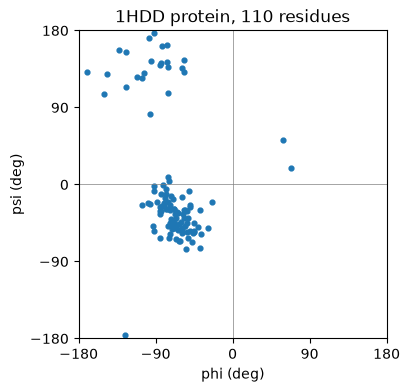

In [67]:
import matplotlib.pyplot as plt

complex_cif_text = fetch_cif("1HDD")
complex_pose_stack = pose_stack_from_file(io.StringIO(complex_cif_text), device, param_db=param_db)

# blocks=None measures every block; the DNA declares no phi/psi and comes back empty
backbone = get_named_torsions(complex_pose_stack, 0, None, ["phi", "psi"])[0]
phi_psi = np.array([[torsions["phi"], torsions["psi"]] for torsions in backbone if {"phi", "psi"} <= torsions.keys()])
# chain-terminal residues measure nan
phi_psi = phi_psi[~np.isnan(phi_psi).any(axis=1)]

# plot a Ramachandran plot for 1HDD
fig, ax = plt.subplots(figsize=(4, 4))
ax.scatter(phi_psi[:, 0], phi_psi[:, 1], s=12)
ax.axhline(0, color="gray", linewidth=0.5)
ax.axvline(0, color="gray", linewidth=0.5)
ax.set(
    xlim=(-180, 180), ylim=(-180, 180), xticks=range(-180, 181, 90), yticks=range(-180, 181, 90),
    xlabel="phi (deg)", ylabel="psi (deg)", title=f"1HDD protein, {len(phi_psi)} residues", aspect="equal",
)
plt.show()

In this example, we use `set_named_torsions` to perturb DNA torsions in two ways:
- setting an `alpha` torsion directly, illustrating downstream "lever-arm" effects
- concerted movement via an alpha/gamma "crankshaft", alpha and gamma turn by opposite amounts, so the nucleotide's backbone changes locally while the swing downstream mostly cancels.

In [68]:
def max_block_move(before, after, block):
    """Largest atom displacement within one block of pose 0, in A."""
    start = int(before.block_coord_offset64[0, block])
    end = start + before.block_type(0, block).n_atoms
    return float((after.coords[0, start:end] - before.coords[0, start:end]).norm(dim=-1).max())


# the middle nucleotide of the first DNA strand, and that strand's 3' end
alphas = get_named_torsions(complex_pose_stack, 0, None, "alpha")[0]
chain_ids = complex_pose_stack.chain_id[0].cpu().numpy()
first_dna_block = next(block for block, torsions in enumerate(alphas) if "alpha" in torsions)
strand = np.flatnonzero(chain_ids == chain_ids[first_dna_block])
dna_block, three_prime_block = int(strand[len(strand) // 2]), int(strand[-1])

start = get_named_torsions(complex_pose_stack, 0, dna_block, ["alpha", "gamma"])

# alpha alone: the whole strand 3' of dna_block swings
alpha_only = set_named_torsions(complex_pose_stack, 0, dna_block, "alpha", start["alpha"] + 5.0)
# crankshaft: gamma turned back by the same amount, both set in one call
crankshaft = set_named_torsions(
    complex_pose_stack, 0, [dna_block, dna_block], ["alpha", "gamma"],
    [start["alpha"] + 5.0, start["gamma"] - 5.0],
)

notes = {"original": f"block {dna_block}: alpha={start['alpha']:.1f}, gamma={start['gamma']:.1f} deg"}
for label, moved in [("alpha +5", alpha_only), ("alpha +5, gamma -5", crankshaft)]:
    notes[label] = f"3' end moved {max_block_move(complex_pose_stack, moved, three_prime_block):.2f} A"
for label, note in notes.items():
    print(f"{label}: {note}")

display(tmol.overlay_view(
    {"original": complex_pose_stack, "alpha +5": alpha_only, "alpha +5, gamma -5": crankshaft},
    notes=notes,
))

original: block 10: alpha=-155.8, gamma=71.4 deg
alpha +5: 3' end moved 3.17 A
alpha +5, gamma -5: 3' end moved 0.98 A


/home/runner/work/tmol/tmol/.venv/lib/python3.12/site-packages/biotite/structure/io/pdb/file.py:629: DeprecationWarning: The chararray class is deprecated and will be removed in a future release. Use an ndarray with a string or bytes dtype instead.
  record = np.char.array(np.where(array.hetero, "HETATM", "ATOM"))
/home/runner/work/tmol/tmol/.venv/lib/python3.12/site-packages/biotite/structure/io/pdb/file.py:629: DeprecationWarning: The chararray class is deprecated and will be removed in a future release. Use an ndarray with a string or bytes dtype instead.
  record = np.char.array(np.where(array.hetero, "HETATM", "ATOM"))
/home/runner/work/tmol/tmol/.venv/lib/python3.12/site-packages/biotite/structure/io/pdb/file.py:629: DeprecationWarning: The chararray class is deprecated and will be removed in a future release. Use an ndarray with a string or bytes dtype instead.
  record = np.char.array(np.where(array.hetero, "HETATM", "ATOM"))
/home/runner/work/tmol/tmol/.venv/lib/python3.12/sit

/home/runner/work/tmol/tmol/.venv/lib/python3.12/site-packages/biotite/structure/io/pdb/file.py:629: DeprecationWarning: The chararray class is deprecated and will be removed in a future release. Use an ndarray with a string or bytes dtype instead.
  record = np.char.array(np.where(array.hetero, "HETATM", "ATOM"))


#### "Autogenerated" named torsions for ligands

A prepared ligand's rotatable bonds become named torsions too, named `chi1`, `chi2`, ... in the order they were found when the ligand was prepared. As there is no rule for determining these, the definitions of torsions have to be queried.  The following example shows this for biotin in 1STP. Loading it with `prepare_ligands=True` builds biotin's parameters on the fly, torsions included.

In [69]:
# prepare_ligands=True parameterizes biotin automatically, no params file needed;
# ligand_seed fixes the generated conformer, which also fixes the chi numbering
ligand_cif_text = fetch_cif("1STP")
ligand_pose_stack = pose_stack_from_file(
    io.StringIO(ligand_cif_text), device, param_db=param_db, prepare_ligands=True, ligand_seed=SEED
)

# the one ligand block in the pose
ligand_block = int(torch.nonzero(tmol.get_ligand_mask(ligand_pose_stack)[0])[0])
ligand_block_type = ligand_pose_stack.block_type(0, ligand_block)
print(f"ligand {ligand_block_type.name3} at block {ligand_block}")

# each named torsion is defined by four atoms of the ligand
for torsion in ligand_block_type.torsions:
    atoms = "-".join(atom.atom for atom in (torsion.a, torsion.b, torsion.c, torsion.d))
    print(f"{torsion.name}: {atoms}")

# label the ligand's heavy atoms by name, and each torsion at the midpoint of the bond it turns
offset = int(ligand_pose_stack.block_coord_offset64[0, ligand_block])
coords = ligand_pose_stack.coords[0].detach().cpu()
viewer = tmol.view(ligand_pose_stack, zoom_to={"resn": ligand_block_type.name3})
viewer.addPropertyLabels(
    "atom", {"resn": ligand_block_type.name3, "not": {"elem": "H"}},
    {"fontSize": 10, "fontColor": "black", "backgroundColor": "white", "backgroundOpacity": 0.8, "alignment": "center"},
)
for torsion in ligand_block_type.torsions:
    bond_start, bond_end = (coords[offset + ligand_block_type.atom_to_idx[atom.atom]] for atom in (torsion.b, torsion.c))
    x, y, z = ((bond_start + bond_end) / 2).tolist()
    viewer.addLabel(
        torsion.name,
        {"position": {"x": x, "y": y, "z": z}, "fontSize": 12, "backgroundColor": "#e83e8c", "backgroundOpacity": 0.8},
    )
viewer.show()

ligand BTN at block 121
chi1: C2-C7-C8-C9
chi2: C8-C7-C2-C4
chi3: C7-C8-C9-C10
chi4: C8-C9-C10-C11
chi5: C9-C10-C11-O11


/home/runner/work/tmol/tmol/.venv/lib/python3.12/site-packages/biotite/structure/io/pdb/file.py:629: DeprecationWarning: The chararray class is deprecated and will be removed in a future release. Use an ndarray with a string or bytes dtype instead.
  record = np.char.array(np.where(array.hetero, "HETATM", "ATOM"))


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

With definitions in hand we can now perturb `chi2` (C7-C2 bond):

In [70]:
# rotate chi2 by +15 and +30 degrees from its current value
before_chi2 = get_named_torsions(ligand_pose_stack, 0, ligand_block, "chi2")
views = {"original": ligand_pose_stack}
notes = {"original": f"chi2={before_chi2:.1f} deg"}
for delta in (15.0, 30.0):
    label = f"chi2 +{delta:.0f} deg"
    views[label] = set_named_torsions(ligand_pose_stack, 0, ligand_block, "chi2", before_chi2 + delta)
    notes[label] = f"chi2={get_named_torsions(views[label], 0, ligand_block, 'chi2'):.1f} deg"
    print(f"{label}: {notes[label]}")

display(tmol.overlay_view(views, notes=notes))

/home/runner/work/tmol/tmol/.venv/lib/python3.12/site-packages/biotite/structure/io/pdb/file.py:629: DeprecationWarning: The chararray class is deprecated and will be removed in a future release. Use an ndarray with a string or bytes dtype instead.
  record = np.char.array(np.where(array.hetero, "HETATM", "ATOM"))
/home/runner/work/tmol/tmol/.venv/lib/python3.12/site-packages/biotite/structure/io/pdb/file.py:629: DeprecationWarning: The chararray class is deprecated and will be removed in a future release. Use an ndarray with a string or bytes dtype instead.
  record = np.char.array(np.where(array.hetero, "HETATM", "ATOM"))
/home/runner/work/tmol/tmol/.venv/lib/python3.12/site-packages/biotite/structure/io/pdb/file.py:629: DeprecationWarning: The chararray class is deprecated and will be removed in a future release. Use an ndarray with a string or bytes dtype instead.
  record = np.char.array(np.where(array.hetero, "HETATM", "ATOM"))


chi2 +15 deg: chi2=-152.6 deg
chi2 +30 deg: chi2=-137.6 deg


/home/runner/work/tmol/tmol/.venv/lib/python3.12/site-packages/biotite/structure/io/pdb/file.py:629: DeprecationWarning: The chararray class is deprecated and will be removed in a future release. Use an ndarray with a string or bytes dtype instead.
  record = np.char.array(np.where(array.hetero, "HETATM", "ATOM"))
/home/runner/work/tmol/tmol/.venv/lib/python3.12/site-packages/biotite/structure/io/pdb/file.py:629: DeprecationWarning: The chararray class is deprecated and will be removed in a future release. Use an ndarray with a string or bytes dtype instead.
  record = np.char.array(np.where(array.hetero, "HETATM", "ATOM"))
/home/runner/work/tmol/tmol/.venv/lib/python3.12/site-packages/biotite/structure/io/pdb/file.py:629: DeprecationWarning: The chararray class is deprecated and will be removed in a future release. Use an ndarray with a string or bytes dtype instead.
  record = np.char.array(np.where(array.hetero, "HETATM", "ATOM"))


### FoldForest basic concepts

A `FoldForest` defines the kinematic tree: a single tree, hanging from a virtual root, that covers every residue and says how each residue is placed relative to another. Each edge between residues is one of three kinds (`tmol.EdgeType`):

- `polymer`: a contiguous run of residues connected through their backbone bonds;
- `jump`: a rigid-body transform (orientation and translation) between two residues, which need not be bonded; a `root_jump` is the jump from the virtual root into a residue (`start=-1`);
- `chemical`: a single non-polymer bond between two residues, such as a ligand on a lysine or a glycan on a serine.

`tmol.FoldForest.reasonable_fold_forest(pose_stack)` builds one automatically, rooting each chain at its first residue -- an N-to-C tree per chain, which every example so far has used implicitly.

#### Manipulating a FoldForest explicitly

`FoldForest.from_edges` builds one from a padded `[pose, edge, 4]` array of `(edge_type, start, end, jump_index)` rows. `set_named_torsions` takes an optional `fold_forest=` and moves whichever side of the torsion's bond is downstream of the root. Below, the same phi change is made under the default N->C tree and under a hand-built C->N tree, and the two move opposite ends of the chain.

In [71]:
def print_edges(fold_forest):
    """Print pose 0's fold forest edges."""
    for edge_type, start, end, jump_index in fold_forest.edges[0]:
        print(f"  {tmol.EdgeType(edge_type).name}: {start} -> {end}")


# 1) an extended peptide; phi of its middle residue gets perturbed below
peptide = tmol.extended_pose_stack_from_sequences("AKLFGSW", device=device)
last_block = peptide.max_n_blocks - 1
middle_block = last_block // 2
start_phi = get_named_torsions(peptide, 0, middle_block, "phi")

# 2) the default tree: rooted at the first residue, built N->C
n_to_c_fold_forest = tmol.FoldForest.reasonable_fold_forest(peptide)
print("default (N->C) fold forest:")
print_edges(n_to_c_fold_forest)
moved_n_to_c = set_named_torsions(
    peptide, 0, middle_block, "phi", start_phi + 30.0, fold_forest=n_to_c_fold_forest
)

# 3) a hand-built C->N tree: rooted at the last residue, polymer edge running backward
c_to_n_edges = np.array([[
    [tmol.EdgeType.root_jump, -1, last_block, -1],
    [tmol.EdgeType.polymer, last_block, 0, -1],
]], dtype=np.int64)
c_to_n_fold_forest = tmol.FoldForest.from_edges(c_to_n_edges)
print("C->N fold forest:")
print_edges(c_to_n_fold_forest)
moved_c_to_n = set_named_torsions(
    peptide, 0, middle_block, "phi", start_phi + 30.0, fold_forest=c_to_n_fold_forest
)

# same phi change, opposite ends of the chain move
notes = {"original": f"phi={start_phi:.1f} deg"}
for label, moved in [("N->C tree", moved_n_to_c), ("C->N tree", moved_c_to_n)]:
    notes[label] = (
        f"phi +30: first residue moved {max_block_move(peptide, moved, 0):.2f} A, "
        f"last residue moved {max_block_move(peptide, moved, last_block):.2f} A"
    )
    print(f"{label}: {notes[label]}")

display(tmol.overlay_view({"original": peptide, "N->C tree": moved_n_to_c, "C->N tree": moved_c_to_n}, notes=notes))

default (N->C) fold forest:
  root_jump: -1 -> 0
  polymer: 0 -> 6
C->N fold forest:
  root_jump: -1 -> 6
  polymer: 6 -> 0
N->C tree: phi +30: first residue moved 0.00 A, last residue moved 5.88 A
C->N tree: phi +30: first residue moved 3.25 A, last residue moved 0.00 A


/home/runner/work/tmol/tmol/.venv/lib/python3.12/site-packages/biotite/structure/io/pdb/file.py:629: DeprecationWarning: The chararray class is deprecated and will be removed in a future release. Use an ndarray with a string or bytes dtype instead.
  record = np.char.array(np.where(array.hetero, "HETATM", "ATOM"))
/home/runner/work/tmol/tmol/.venv/lib/python3.12/site-packages/biotite/structure/io/pdb/file.py:629: DeprecationWarning: The chararray class is deprecated and will be removed in a future release. Use an ndarray with a string or bytes dtype instead.
  record = np.char.array(np.where(array.hetero, "HETATM", "ATOM"))
/home/runner/work/tmol/tmol/.venv/lib/python3.12/site-packages/biotite/structure/io/pdb/file.py:629: DeprecationWarning: The chararray class is deprecated and will be removed in a future release. Use an ndarray with a string or bytes dtype instead.
  record = np.char.array(np.where(array.hetero, "HETATM", "ATOM"))
/home/runner/work/tmol/tmol/.venv/lib/python3.12/sit

#### Jumps: keeping a ligand on its pocket

`reasonable_fold_forest` gives an unbonded ligand its own root jump, so it stays fixed in space: bend the protein's backbone upstream of the binding site and the pocket swings away from the ligand. That is rarely wanted in torsion-space minimization or relax of a complex. A `jump` edge from a pocket residue to the ligand makes the ligand ride along with its pocket instead. The jump's six degrees of freedom are then the ligand's rigid-body placement relative to that residue, which a `MoveMap` can free for rigid-body refinement. This is the same `fold_forest` that `run_kin_min` takes.

Below, the 1STP biotin from the ligand section is hung from Ser45, which hydrogen-bonds it in the pocket, and the same backbone psi change is made under both trees.

In [72]:
# hang biotin from Ser45 instead of giving it its own root jump;
# a jump must start where an edge ends, so the protein's polymer edge is split at Ser45
pocket_block = tmol.block_for_residue_label(ligand_pose_stack, 0, "A", "45")
default_fold_forest = tmol.FoldForest.reasonable_fold_forest(ligand_pose_stack)
pocket_fold_forest = tmol.FoldForest.from_edges(np.array([[
    [tmol.EdgeType.root_jump, -1, 0, -1],
    [tmol.EdgeType.polymer, 0, pocket_block, -1],
    [tmol.EdgeType.polymer, pocket_block, ligand_block - 1, -1],
    [tmol.EdgeType.jump, pocket_block, ligand_block, 0],
]], dtype=np.int64))

# bend the backbone 5 residues upstream of the pocket under each tree
hinge_block = pocket_block - 5
hinge_psi = get_named_torsions(ligand_pose_stack, 0, hinge_block, "psi")
views, notes = {"original": ligand_pose_stack}, {"original": "unmoved"}
for label, fold_forest in [("default tree", default_fold_forest), ("ligand on Ser45", pocket_fold_forest)]:
    print(f"{label}:")
    print_edges(fold_forest)
    views[label] = set_named_torsions(
        ligand_pose_stack, 0, hinge_block, "psi", hinge_psi + 30.0, fold_forest=fold_forest
    )
    notes[label] = (
        f"pocket moved {max_block_move(ligand_pose_stack, views[label], pocket_block):.1f} A, "
        f"ligand moved {max_block_move(ligand_pose_stack, views[label], ligand_block):.1f} A"
    )
    print(f"  {notes[label]}")

display(tmol.overlay_view(views, notes=notes))

default tree:
  root_jump: -1 -> 0
  polymer: 0 -> 120
  root_jump: -1 -> 121
  pocket moved 7.7 A, ligand moved 0.0 A
ligand on Ser45:
  root_jump: -1 -> 0
  polymer: 0 -> 32
  polymer: 32 -> 120
  jump: 32 -> 121
  pocket moved 7.7 A, ligand moved 10.3 A


/home/runner/work/tmol/tmol/.venv/lib/python3.12/site-packages/biotite/structure/io/pdb/file.py:629: DeprecationWarning: The chararray class is deprecated and will be removed in a future release. Use an ndarray with a string or bytes dtype instead.
  record = np.char.array(np.where(array.hetero, "HETATM", "ATOM"))
/home/runner/work/tmol/tmol/.venv/lib/python3.12/site-packages/biotite/structure/io/pdb/file.py:629: DeprecationWarning: The chararray class is deprecated and will be removed in a future release. Use an ndarray with a string or bytes dtype instead.
  record = np.char.array(np.where(array.hetero, "HETATM", "ATOM"))
/home/runner/work/tmol/tmol/.venv/lib/python3.12/site-packages/biotite/structure/io/pdb/file.py:629: DeprecationWarning: The chararray class is deprecated and will be removed in a future release. Use an ndarray with a string or bytes dtype instead.
  record = np.char.array(np.where(array.hetero, "HETATM", "ATOM"))
/home/runner/work/tmol/tmol/.venv/lib/python3.12/sit

/home/runner/work/tmol/tmol/.venv/lib/python3.12/site-packages/biotite/structure/io/pdb/file.py:629: DeprecationWarning: The chararray class is deprecated and will be removed in a future release. Use an ndarray with a string or bytes dtype instead.
  record = np.char.array(np.where(array.hetero, "HETATM", "ATOM"))
/home/runner/work/tmol/tmol/.venv/lib/python3.12/site-packages/biotite/structure/io/pdb/file.py:629: DeprecationWarning: The chararray class is deprecated and will be removed in a future release. Use an ndarray with a string or bytes dtype instead.
  record = np.char.array(np.where(array.hetero, "HETATM", "ATOM"))


## 8. Advanced Topics

Two more advanced topics: a) _designing_ sequences using tmol's `pack_rotamers`, and b) a few examples illustrating how to use tmol _inside_ a machine-learning model, where gradients through tmol need to survive backpropagation.

### Design with pack_rotamers

The tmol function `pack_rotamers` carries out discrete optimization of sidechain identities and conformations, with per-amino-acid options controlled by a `PackerTask`.  We have previously only seen the packer used in conjunction with `restrict_to_repacking`, which only samples conformations of the input amino acids.  However, a `PackerTask` without this option set can be used to change residue identities.

The block below shows how the packer may be used for sequence redesign, by redesigning the core of ubiquitin to all hydrophobic residues.  Several new concepts are introduced:
- Showing per-residue control of a `PackerTask`
- `restrict_absent_name3s` to offer more control over design, restricting to a subset of all amino acids

#### Redesigning the core

In [73]:
cif_text = fetch_cif("1UBQ")
pose_stack = pose_stack_from_file(io.StringIO(cif_text), device, param_db=param_db)
score_function = beta2016_score_function(device, param_db=param_db)

# ubiquitin's buried core, by PDB residue number
core_mask = torch.zeros((1, pose_stack.max_n_blocks), dtype=torch.bool, device=device)
core_residues = torch.tensor([3, 5, 13, 15, 17, 26, 30, 43, 50, 56, 61, 67])
core_mask[0, tmol.blocks_for_residue_labels(pose_stack, 0, "A", core_residues)] = True
samplers = [create_dunbrack_sampler_from_database(param_db, device), FixedAAChiSampler(), IncludeCurrentSampler()]


def design_core(task):
    """Task operation: design the core to hydrophobics and repack everything else."""
    task.restrict_to_repacking(~core_mask)
    task.restrict_absent_name3s({"ALA", "VAL", "LEU", "ILE", "PHE", "MET"}, core_mask)
    for sampler in samplers:
        task.add_conformer_sampler(sampler)


def design_summary(designed, mask):
    """Total score and the mutations within mask, e.g. ILE13VAL."""
    residue_numbers = pose_stack.pdb_info.residue_labels[0]
    mutations = [
        f"{pose_stack.block_type(0, block).name3}{residue_numbers[block]}{designed.block_type(0, block).name3}"
        for block in torch.nonzero(mask[0]).flatten().tolist()
        if designed.block_type(0, block).name3 != pose_stack.block_type(0, block).name3
    ]
    score = float(score_function.render_whole_pose_scoring_module(designed)(designed.coords).sum())
    return f"score {score:.1f}; mutations: {', '.join(mutations) or 'none'}"


task = PackerTask(pose_stack, PackerPalette())
design_core(task)
torch.manual_seed(SEED)
packer_design = pack_rotamers(pose_stack, score_function, task)

core_notes = {"original": design_summary(pose_stack, core_mask), "packer design": design_summary(packer_design, core_mask)}
for label, note in core_notes.items():
    print(f"{label}: {note}")

display(tmol.overlay_view({"original": pose_stack, "packer design": packer_design}, notes=core_notes))

original: score 195.1; mutations: none
packer design: score -96.8; mutations: ILE13VAL, ILE61VAL


/home/runner/work/tmol/tmol/.venv/lib/python3.12/site-packages/biotite/structure/io/pdb/file.py:629: DeprecationWarning: The chararray class is deprecated and will be removed in a future release. Use an ndarray with a string or bytes dtype instead.
  record = np.char.array(np.where(array.hetero, "HETATM", "ATOM"))
/home/runner/work/tmol/tmol/.venv/lib/python3.12/site-packages/biotite/structure/io/pdb/file.py:629: DeprecationWarning: The chararray class is deprecated and will be removed in a future release. Use an ndarray with a string or bytes dtype instead.
  record = np.char.array(np.where(array.hetero, "HETATM", "ATOM"))
/home/runner/work/tmol/tmol/.venv/lib/python3.12/site-packages/biotite/structure/io/pdb/file.py:629: DeprecationWarning: The chararray class is deprecated and will be removed in a future release. Use an ndarray with a string or bytes dtype instead.
  record = np.char.array(np.where(array.hetero, "HETATM", "ATOM"))
/home/runner/work/tmol/tmol/.venv/lib/python3.12/sit

#### Design inside relax

A `PackerTask` allowing design can also be passed into `fast_relax`.  This results in a design pipeline alternating sequence design and all-atom minimization.  Note that the reported relaxed score also includes _minimization_, so it is not directly comparable to the packer-only score above.

In [74]:
# the same task operation, applied at every packing step of relax
torch.manual_seed(SEED)
relax_design = tmol.fast_relax(
    pose_stack.clone(), score_function, PackerPalette(), tmol.CartesianMoveMap(),
    tmol.FoldForest.reasonable_fold_forest(pose_stack), num_repeats=1, task_operations=[design_core],
)

core_notes["design in relax"] = design_summary(relax_design, core_mask)
print(f"design in relax: {core_notes['design in relax']}")

display(tmol.overlay_view(
    {"original": pose_stack, "packer design": packer_design, "design in relax": relax_design}, notes=core_notes
))

design in relax: score -267.3; mutations: ILE3VAL, VAL5PHE, VAL17LEU, VAL26ALA, LEU43ILE


/home/runner/work/tmol/tmol/.venv/lib/python3.12/site-packages/biotite/structure/io/pdb/file.py:629: DeprecationWarning: The chararray class is deprecated and will be removed in a future release. Use an ndarray with a string or bytes dtype instead.
  record = np.char.array(np.where(array.hetero, "HETATM", "ATOM"))
/home/runner/work/tmol/tmol/.venv/lib/python3.12/site-packages/biotite/structure/io/pdb/file.py:629: DeprecationWarning: The chararray class is deprecated and will be removed in a future release. Use an ndarray with a string or bytes dtype instead.
  record = np.char.array(np.where(array.hetero, "HETATM", "ATOM"))
/home/runner/work/tmol/tmol/.venv/lib/python3.12/site-packages/biotite/structure/io/pdb/file.py:629: DeprecationWarning: The chararray class is deprecated and will be removed in a future release. Use an ndarray with a string or bytes dtype instead.
  record = np.char.array(np.where(array.hetero, "HETATM", "ATOM"))
/home/runner/work/tmol/tmol/.venv/lib/python3.12/sit

#### Design with noncanonical residues

The `PackerPalette` decides which residue types are candidates at all, before the `PackerTask` further restricts candidates. The default palette offers only canonical L residues (plus glycine); `PackerPalette(noncanonical_design=True)` also includes AIB (alpha-aminoisobutyric acid) and D-amino acids. The following example shows design of several solvent-exposed helical positions, allowing both AIB and D-ALA in addition to the original identity.

In [75]:
# solvent-facing positions on ubiquitin's helix (residues 23-34)
helix_mask = torch.zeros_like(core_mask)
helix_blocks = tmol.blocks_for_residue_labels(pose_stack, 0, "A", torch.tensor([25, 28, 29, 32, 33]))
helix_mask[0, helix_blocks] = True

# the default palette offers only canonical L residues; noncanonical_design adds the rest
pbt = pose_stack.packed_block_types
offered = {}
for palette in (PackerPalette(), PackerPalette(noncanonical_design=True)):
    palette_task = PackerTask(pose_stack, palette)
    considered = palette_task.per_block_considered_block_types[0, int(helix_blocks[0])].tolist()
    offered[palette.noncanonical_design] = {pbt.active_block_types[i].name3 for i in considered if i >= 0}
print("noncanonical_design=True also offers:", sorted(offered[True] - offered[False]))

# offer D-alanine (DAL), AIB, or the native residue at each helix position
helix_task = PackerTask(pose_stack, PackerPalette(noncanonical_design=True))
helix_task.restrict_to_repacking(~helix_mask)
for block in helix_blocks.tolist():
    block_mask = torch.zeros_like(helix_mask)
    block_mask[0, block] = True
    helix_task.restrict_absent_name3s({"DAL", "AIB", pose_stack.block_type(0, block).name3}, block_mask)
for sampler in samplers:
    helix_task.add_conformer_sampler(sampler)

torch.manual_seed(SEED)
helix_design = pack_rotamers(pose_stack, score_function, helix_task)

helix_notes = {"original": design_summary(pose_stack, helix_mask), "helix design": design_summary(helix_design, helix_mask)}
for label, note in helix_notes.items():
    print(f"{label}: {note}")

display(tmol.overlay_view({"original": pose_stack, "helix design": helix_design}, notes=helix_notes))

noncanonical_design=True also offers: ['AIB', 'DAL', 'DAR', 'DAS', 'DCY', 'DGL', 'DGN', 'DHI', 'DIL', 'DLE', 'DLY', 'DPN', 'DPR', 'DSG', 'DSN', 'DTH', 'DTR', 'DTY', 'DVA', 'MED']


original: score 195.1; mutations: none
helix design: score -97.0; mutations: ASN25AIB, ASP32AIB


/home/runner/work/tmol/tmol/.venv/lib/python3.12/site-packages/biotite/structure/io/pdb/file.py:629: DeprecationWarning: The chararray class is deprecated and will be removed in a future release. Use an ndarray with a string or bytes dtype instead.
  record = np.char.array(np.where(array.hetero, "HETATM", "ATOM"))
/home/runner/work/tmol/tmol/.venv/lib/python3.12/site-packages/biotite/structure/io/pdb/file.py:629: DeprecationWarning: The chararray class is deprecated and will be removed in a future release. Use an ndarray with a string or bytes dtype instead.
  record = np.char.array(np.where(array.hetero, "HETATM", "ATOM"))
/home/runner/work/tmol/tmol/.venv/lib/python3.12/site-packages/biotite/structure/io/pdb/file.py:629: DeprecationWarning: The chararray class is deprecated and will be removed in a future release. Use an ndarray with a string or bytes dtype instead.
  record = np.char.array(np.where(array.hetero, "HETATM", "ATOM"))
/home/runner/work/tmol/tmol/.venv/lib/python3.12/sit

### tmol as a differentiable loss

One advantage of tmol is that every step from an input coordinate (or internal coordinate) tensor to score is a torch operation. A model that emits coordinates can therefore use tmol energy as a loss term, and backpropogation (via `.backward()`) works through tmol like any other torch module.  Support varies depending on the input coordinate representation:

1. **atom37**, an `Ntokenx37x3`tensor format used by AtomWorks, is supported directly.
2. **Any other layout** needs a small interface layer that routes the model's coordinates into tmol's atoms.

Examples of both are shown below.

#### Mode 1: atom37 -- a tmol loss for a structure refiner

`pose_stack_from_canonical_aa_atom37` builds poses from atom37 coordinates, AtomWorks residue tokens and chain ids alone; `atomworks_from_pose_stack` goes the other way and is used here to make training targets. Token 0 marks padding, so proteins of different lengths share one batch. (For noncanonical residues or ligands in an atom37-like layout, `pose_stack_from_atom37` takes the same tensors plus a `PoseBuildContext` that supplies the chemistry.)

In [76]:
from tmol.io import ATOMWORKS_ATOM37_NAMES, atomworks_from_pose_stack, pose_stack_from_canonical_aa_atom37

# training targets: ubiquitin and Trp-cage as one atom37 batch; the shorter one is padded with token 0
targets = PoseStackBuilder.from_poses(
    [pose_stack_from_file(io.StringIO(fetch_cif(pdb_id)), device, param_db=param_db) for pdb_id in ("1UBQ", "1L2Y")],
    device,
)
true_coords, residue_type, chain_iid = atomworks_from_pose_stack(targets)
present = (true_coords != 0).any(dim=-1, keepdim=True)  # absent atom37 slots are 0
n_residues = int((residue_type > 0).sum())
print(f"atom37 batch {tuple(true_coords.shape)}, real residues per pose {(residue_type > 0).sum(dim=1).tolist()}")

atom37_score_function = beta2016_score_function(device)


def atom37_energies(coords, sum_terms=True):
    """Build poses from atom37 tensors and score them, keeping the autograd graph."""
    pose_stack = pose_stack_from_canonical_aa_atom37(coords, residue_type, chain_iid)
    scorer = atom37_score_function.render_whole_pose_scoring_module(pose_stack)
    return scorer(pose_stack.coords, sum_terms=sum_terms)

atom37 batch (2, 76, 37, 3), real residues per pose [76, 20]


The model is a deliberately small refiner: for each residue, an MLP reads the atoms of residues i-1, i and i+1 (relative to residue i's CA) plus a residue-type embedding, and predicts a correction to residue i's atoms. It learns to clean up noisy coordinates.

In [77]:
ca_slot = ATOMWORKS_ATOM37_NAMES["ALA"].index("CA")


class NeighborRefiner(torch.nn.Module):
    """Predict a correction for each atom37 slot from residues i-1, i, i+1, centered on CA_i."""

    def __init__(self, hidden=256):
        super().__init__()
        self.embed = torch.nn.Embedding(21, 16)
        self.mlp = torch.nn.Sequential(
            torch.nn.Linear(3 * 37 * 3 + 16, hidden), torch.nn.ReLU(),
            torch.nn.Linear(hidden, hidden), torch.nn.ReLU(),
            torch.nn.Linear(hidden, 37 * 3),
        )

    def forward(self, coords):
        n_tokens = coords.shape[1]
        position = torch.arange(n_tokens, device=coords.device)
        ca = coords[:, :, ca_slot : ca_slot + 1]
        features = [self.embed(residue_type)]
        for shift in (1, 0, -1):
            # a neighbor counts only if it exists, is a real residue, and is in the same chain
            in_range = (position - shift >= 0) & (position - shift < n_tokens)
            real_neighbor = (chain_iid.roll(shift, 1) == chain_iid) & (residue_type.roll(shift, 1) > 0) & in_range
            keep = present.roll(shift, 1) & real_neighbor[..., None, None]
            features.append(((coords.roll(shift, 1) - ca) * keep).flatten(2))
        correction = self.mlp(torch.cat(features, dim=-1)).view_as(coords)
        return coords + correction * present


def noisy(generator, sigma=0.3):
    """The true coordinates with Gaussian noise (sigma in A) on every present atom."""
    noise = torch.randn(true_coords.shape, generator=generator, device=device)
    return true_coords + sigma * noise * present


def rmsd(coords):
    """RMSD to the true coordinates over present atoms, in A."""
    squared = ((coords - true_coords) ** 2).sum(dim=-1, keepdim=True) * present
    return float((squared.sum() / present.sum()).sqrt())


def fit(model, steps, energy_weight, lr, seed):
    """Train on fresh noise each step; loss = MSE + energy_weight * tmol energy per residue."""
    model = model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    generator = torch.Generator(device=device).manual_seed(seed)
    for _ in range(steps):
        predicted = model(noisy(generator))
        loss = (((predicted - true_coords) ** 2) * present).sum() / present.sum()
        if energy_weight:
            loss = loss + energy_weight * atom37_energies(predicted).sum() / n_residues
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    return model

Coordinate MSE alone already pulls the model toward the true structure, so a tmol term helps most once MSE has done what it can: the remaining errors are geometry that MSE averages away. The realistic recipe is to pretrain on MSE and then fine-tune with the energy added. Below, a pretrained refiner is fine-tuned two ways for the same number of steps -- more MSE, or MSE plus 0.01 x tmol energy per residue -- and both are compared on noise neither saw.

In [78]:
import copy

# 1) pretrain on MSE alone
torch.manual_seed(SEED)
pretrained = fit(NeighborRefiner(), steps=2000, energy_weight=0.0, lr=1e-3, seed=SEED)

# 2) fine-tune two copies on the same data: more MSE, or MSE plus the tmol energy
refiners = {
    "MSE": fit(copy.deepcopy(pretrained), steps=500, energy_weight=0.0, lr=3e-4, seed=SEED + 1),
    "MSE + tmol": fit(copy.deepcopy(pretrained), steps=500, energy_weight=0.01, lr=3e-4, seed=SEED + 1),
}

# 3) compare on noise neither model saw
eval_input = noisy(torch.Generator(device=device).manual_seed(SEED + 2))
term_names = [score_type.name for score_type in atom37_score_function.all_score_types()]
outputs, notes = {"true": true_coords, "noisy input": eval_input}, {}
with torch.no_grad():
    outputs.update({label: refiner(eval_input) for label, refiner in refiners.items()})
    for label, coords in outputs.items():
        terms = atom37_energies(coords, sum_terms=False).sum(dim=-1)
        bonded = sum(float(terms[term_names.index(name)]) for name in ("cart_lengths", "cart_angles"))
        notes[label] = f"RMSD {rmsd(coords):.2f} A, energy {float(terms.sum()):.1f}, bond lengths + angles {bonded:.1f}"
        print(f"{label:12s} {notes[label]}")

    # ubiquitin (pose 0) from each model
    views = {
        label: pose_stack_from_canonical_aa_atom37(coords[:1], residue_type[:1], chain_iid[:1])
        for label, coords in outputs.items()
    }
display(tmol.overlay_view(views, notes=notes))

true         RMSD 0.00 A, energy 298.0, bond lengths + angles 130.7
noisy input  RMSD 0.50 A, energy 21063.4, bond lengths + angles 16359.7
MSE          RMSD 0.19 A, energy 1139.8, bond lengths + angles 751.0
MSE + tmol   RMSD 0.20 A, energy 761.1, bond lengths + angles 642.0


/home/runner/work/tmol/tmol/.venv/lib/python3.12/site-packages/biotite/structure/io/pdb/file.py:629: DeprecationWarning: The chararray class is deprecated and will be removed in a future release. Use an ndarray with a string or bytes dtype instead.
  record = np.char.array(np.where(array.hetero, "HETATM", "ATOM"))
/home/runner/work/tmol/tmol/.venv/lib/python3.12/site-packages/biotite/structure/io/pdb/file.py:629: DeprecationWarning: The chararray class is deprecated and will be removed in a future release. Use an ndarray with a string or bytes dtype instead.
  record = np.char.array(np.where(array.hetero, "HETATM", "ATOM"))
/home/runner/work/tmol/tmol/.venv/lib/python3.12/site-packages/biotite/structure/io/pdb/file.py:629: DeprecationWarning: The chararray class is deprecated and will be removed in a future release. Use an ndarray with a string or bytes dtype instead.
  record = np.char.array(np.where(array.hetero, "HETATM", "ATOM"))
/home/runner/work/tmol/tmol/.venv/lib/python3.12/sit

#### Mode 2: a custom layout -- all-atom output of a co-folding model

Co-folding models in the AlphaFold3 family emit one flat `[n_atoms, 3]` tensor covering protein and ligand atoms together, which atom37 cannot represent. The interface layer below is written once per topology: it assigns each atom a token and a slot (one token per polymer residue, one per ligand atom, as AF3 tokenizes), and `prepare_atom37_pose_builder` binds that routing to tmol's chemistry, ligand parameters included. Each call is then a differentiable scatter and pose construction.

In [79]:
from tmol import atom_array_from_file
from tmol.io import build_context_from_atom_array, prepare_atom37_pose_builder


class FlatAtomLayer:
    """Route a co-folding model's flat [n_atoms, 3] output into a PoseStack.

    Each atom of the model's topology gets a token (one per polymer residue, one per
    ligand atom, as AF3 tokenizes) and a slot within its token. The prepared builder
    binds that routing to tmol's chemistry once; each call is then a differentiable
    scatter plus pose construction.
    """

    def __init__(self, structure, device, param_db):
        structure = structure.copy()
        new_residue = np.r_[
            True,
            (structure.res_id[1:] != structure.res_id[:-1]) | (structure.chain_id[1:] != structure.chain_id[:-1]),
        ]
        new_token = new_residue | structure.hetero
        token_id = np.cumsum(new_token) - 1
        slot = np.arange(len(token_id)) - np.flatnonzero(new_token)[token_id]
        assert slot.max() < 37, "every token must fit in 37 slots"
        structure.set_annotation("token_id", token_id)
        structure.set_annotation("atom37_slot", slot)

        self.context = build_context_from_atom_array(
            structure, device, prepare_ligands=True, param_db=param_db, ligand_seed=SEED
        )
        self.builder = prepare_atom37_pose_builder(structure, self.context)
        self.n_tokens = int(token_id[-1]) + 1
        self.index = (
            torch.zeros(len(token_id), dtype=torch.int64, device=device),
            torch.as_tensor(token_id, device=device),
            torch.as_tensor(slot, device=device),
        )

    def __call__(self, flat_coords):
        """PoseStack from [n_atoms, 3] coordinates; gradients flow back to flat_coords."""
        atom37 = torch.full((1, self.n_tokens, 37, 3), float("nan"), device=flat_coords.device)
        return self.builder(atom37.index_put(self.index, flat_coords))


# the model's topology: heavy atoms of the 1STP complex, as a co-folding model would emit them
complex_structure = atom_array_from_file(io.StringIO(fetch_cif("1STP")))
complex_structure = complex_structure[(complex_structure.element != "H") & (complex_structure.res_name != "HOH")]
layer = FlatAtomLayer(complex_structure, device, param_db)
print(f"{complex_structure.array_length()} atoms in {layer.n_tokens} tokens")

917 atoms in 137 tokens


As a use, take a flawed prediction of the streptavidin-biotin complex, with the ligand shifted into clashes, and refine it by gradient descent on the ligand's flat coordinates, with tmol energy as the objective. The same `complex_energy` could equally be a loss term while training the co-folding model.

In [80]:
complex_score_function = beta2016_score_function(device, param_db=layer.context.parameter_database)


def complex_energy(flat_coords):
    """tmol energy of the complex, differentiable in the flat coordinates."""
    pose_stack = layer(flat_coords)
    return complex_score_function.render_whole_pose_scoring_module(pose_stack)(pose_stack.coords).sum()


true_flat = torch.tensor(complex_structure.coord, dtype=torch.float32, device=device)
is_ligand = torch.as_tensor(complex_structure.hetero, device=device)


def ligand_rmsd(flat_coords):
    """Ligand RMSD to the crystal pose, in A."""
    return float(((flat_coords[is_ligand] - true_flat[is_ligand]) ** 2).sum(dim=-1).mean().sqrt())


# a flawed prediction: biotin shifted 1.5 A into clashes with the protein, plus 0.2 A noise
generator = torch.Generator(device=device).manual_seed(SEED)
predicted = true_flat.clone()
shift = 1.5 * torch.tensor([1.0, 1.0, 0.0], device=device) / 2**0.5
predicted[is_ligand] += shift + 0.2 * torch.randn((int(is_ligand.sum()), 3), generator=generator, device=device)

# refine by gradient descent on the ligand's flat coordinates; the protein stays fixed
ligand_xyz = predicted[is_ligand].clone().requires_grad_(True)
optimizer = torch.optim.Adam([ligand_xyz], lr=0.05)
print(f"crystal: energy {float(complex_energy(true_flat)):.1f}")
for step in range(151):
    flat = predicted.clone()
    flat[is_ligand] = ligand_xyz
    energy = complex_energy(flat)
    if step % 50 == 0:
        print(f"step {step:3d}: energy {float(energy.detach()):.1f}, ligand RMSD {ligand_rmsd(flat.detach()):.2f} A")
    optimizer.zero_grad()
    energy.backward()
    optimizer.step()

refined = predicted.clone()
refined[is_ligand] = ligand_xyz.detach()
display(tmol.overlay_view(
    {"crystal": layer(true_flat), "prediction": layer(predicted), "refined": layer(refined)},
    notes={
        label: f"ligand RMSD {ligand_rmsd(coords):.2f} A"
        for label, coords in [("crystal", true_flat), ("prediction", predicted), ("refined", refined)]
    },
))

crystal: energy 361.4


step   0: energy 941.8, ligand RMSD 1.51 A


step  50: energy 358.9, ligand RMSD 0.63 A


step 100: energy 343.7, ligand RMSD 0.45 A


step 150: energy 338.8, ligand RMSD 0.56 A


/home/runner/work/tmol/tmol/.venv/lib/python3.12/site-packages/biotite/structure/io/pdb/file.py:629: DeprecationWarning: The chararray class is deprecated and will be removed in a future release. Use an ndarray with a string or bytes dtype instead.
  record = np.char.array(np.where(array.hetero, "HETATM", "ATOM"))
/home/runner/work/tmol/tmol/.venv/lib/python3.12/site-packages/biotite/structure/io/pdb/file.py:629: DeprecationWarning: The chararray class is deprecated and will be removed in a future release. Use an ndarray with a string or bytes dtype instead.
  record = np.char.array(np.where(array.hetero, "HETATM", "ATOM"))
/home/runner/work/tmol/tmol/.venv/lib/python3.12/site-packages/biotite/structure/io/pdb/file.py:629: DeprecationWarning: The chararray class is deprecated and will be removed in a future release. Use an ndarray with a string or bytes dtype instead.
  record = np.char.array(np.where(array.hetero, "HETATM", "ATOM"))
/home/runner/work/tmol/tmol/.venv/lib/python3.12/sit